# E123 · What did the wolf eat? Four models between a tuft of hair and a diet, tested on wolves whose meals were written down

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the **captive feeding trial of ten gray wolves** at the Wildlife Science Center, Forest Lake, Minnesota, 2011-2012 (S1 Table of Derbridge et al. 2015, PLoS ONE 10(3): e0119940, CC BY): carbon and nitrogen isotope values of 48 wolf hair samples and of 71 tissue samples of the deer, beaver and geese the wolves were fed, and the record of every carcass each wolf was given. One section simulates a tracer that nobody measured, and says so |
| **You will learn** | Chaining models so that each one feeds the next: a **robust hierarchical measurement model** built on replicate samples · **hierarchical source signatures**, partly pooled over batches of prey · a **Dirichlet mixing model** fitted with NUTS and checked against an exact grid over the simplex · why a "flat" Dirichlet prior is not flat on the question · a **blind test against a known diet** · a **calibration fitted jointly** with the model that uses it · the **value of another tracer** · isotope-space maps with ellipses, ternary posterior densities, a specification curve over 144 analyses |

## The question

A wolf biologist rarely sees a wolf eat. What she can collect is hair, and hair is built from food. The
carbon and nitrogen in a deer differ slightly in their isotopes from those in a beaver or a goose, and a
hair grown over a summer keeps a weighted average of that summer's meals. Reading the average backwards
is the business of a stable-isotope mixing model: given the isotope values of the consumer and of each
possible food, find the proportions of the diet (Phillips and Gregg 2001; Moore and Semmens 2008;
Parnell et al. 2013).

Isotope values are written in delta notation, parts per thousand away from a standard: $\delta^{13}$C
for carbon and $\delta^{15}$N for nitrogen. If a wolf's diet is a share $p_k$ of each prey $k$, with
isotope values $\mu_k$, its hair should sit at

$$\text{hair} = \sum_k p_k\,\mu_k + \Delta ,$$

where $\Delta$ is the discrimination factor, the shift that the animal's own metabolism adds between
food and tissue. Two isotopes give two equations, the shares add to one, and with three prey the
arithmetic closes exactly. That is the textbook picture, and each of its symbols hides a model. The hair
value is measured with error. The prey values are means of a few sampled animals. The discrimination
factor comes from another study, often on another species. And the shares need a prior, which says more
than it seems to.

This notebook builds the chain link by link on data where, for once, the answer is known. Derbridge
and colleagues (2015) kept ten wolves in a wildlife centre for a year, recorded every carcass that went
into their enclosure, and measured the isotopes of the wolves' hair and of a sample of the carcasses.
We do the whole analysis without the feeding record, as a field biologist would have to, and only then
open it. The path, with its dead ends, looks like this.

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse, FancyArrowPatch, FancyBboxPatch

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub; nothing here uses JAX (see E89, E118)

RANDOM_SEED = 123
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
plt.rcParams.update({"axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9})
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
T_START = time.time()

INK, MUTED, LIGHT, GRID = "#222222", "#8a8a8a", "#d9d9d9", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
SEQ = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
ISO = ["d13C", "d15N"]
ISO_LABEL = {"d13C": r"$\delta^{13}$C (‰)", "d15N": r"$\delta^{15}$N (‰)"}
PREY = ["deer", "beaver", "goose"]
PREY_COLOUR = {"deer": BLUE, "beaver": ORANGE, "goose": AQUA}
DIAG = []                                   # sampler diagnostics of every fit, printed as we go


def tidy(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.6)
    ax.set_axisbelow(True)


def note(name, idata):
    """Record divergences, worst r_hat and lowest effective sample size of a fit."""
    rhat, ess = az.rhat(idata), az.ess(idata)
    DIAG.append({"model": name, "divergences": int(idata.sample_stats["diverging"].sum()),
                 "max r_hat": round(max(float(rhat[v].max()) for v in rhat.data_vars), 3),
                 "min ESS": int(min(float(ess[v].min()) for v in ess.data_vars))})


def shares(values, digits=3):
    """Three shares as a plain dictionary, for printing."""
    return {s: round(float(v), digits) for s, v in zip(PREY, values)}


def region(ax, mean, cov, colour, mass=0.9, **kw):
    """Ellipse holding `mass` of a two-dimensional normal distribution."""
    val, vec = np.linalg.eigh(np.asarray(cov, float))
    width, height = 2 * np.sqrt(np.maximum(val, 0) * -2 * np.log(1 - mass))
    angle = np.degrees(np.arctan2(vec[1, 0], vec[0, 0]))
    ax.add_patch(Ellipse(mean, width, height, angle=angle, ec=colour, **{"fc": "none", "lw": 1.6, **kw}))

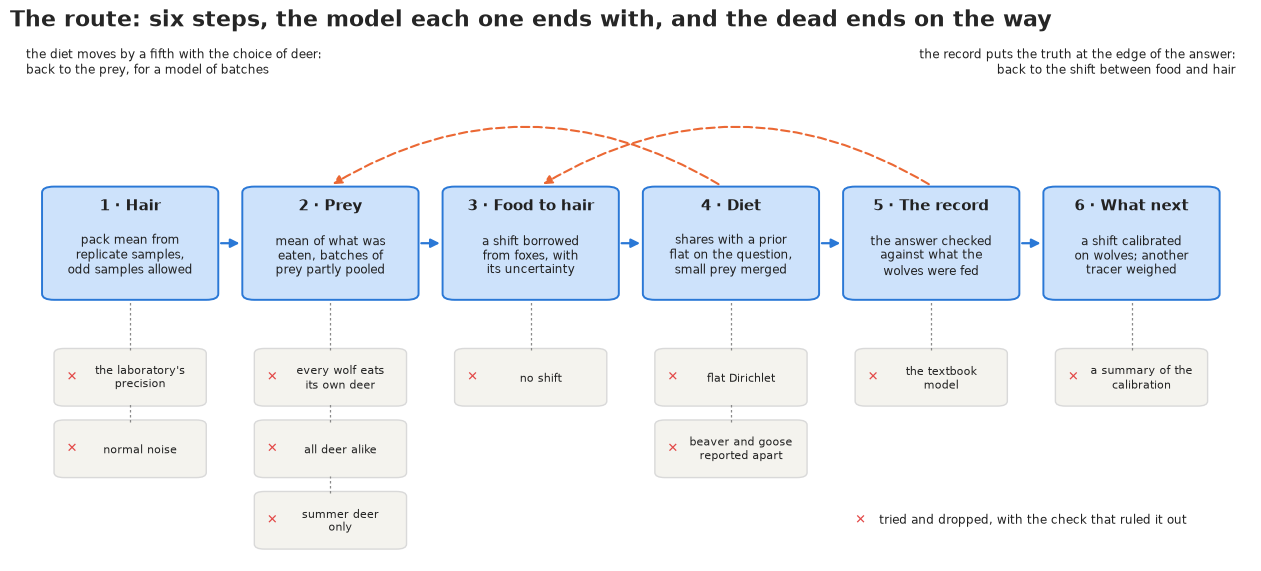

In [2]:
ROUTE = [  # step, what we end up using, what we try and drop on the way
    ("1 · Hair", "pack mean from\nreplicate samples,\nodd samples allowed",
     ["the laboratory's\nprecision", "normal noise"]),
    ("2 · Prey", "mean of what was\neaten, batches of\nprey partly pooled",
     ["every wolf eats\nits own deer", "all deer alike", "summer deer\nonly"]),
    ("3 · Food to hair", "a shift borrowed\nfrom foxes, with\nits uncertainty",
     ["no shift"]),
    ("4 · Diet", "shares with a prior\nflat on the question,\nsmall prey merged",
     ["flat Dirichlet", "beaver and goose\nreported apart"]),
    ("5 · The record", "the answer checked\nagainst what the\nwolves were fed",
     ["the textbook\nmodel"]),
    ("6 · What next", "a shift calibrated\non wolves; another\ntracer weighed",
     ["a summary of the\ncalibration"]),
]

fig, ax = plt.subplots(figsize=(12.5, 5.6))
for i, (step, kept, dropped) in enumerate(ROUTE):
    ax.add_patch(FancyBboxPatch((i - 0.42, 2.55), 0.84, 1.1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc="#cde2fb", ec=BLUE, lw=1.4))
    ax.text(i, 3.47, step, ha="center", va="center", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(i, 2.98, kept, ha="center", va="center", fontsize=8.6, color=INK, linespacing=1.25)
    if i < len(ROUTE) - 1:
        ax.add_patch(FancyArrowPatch((i + 0.44, 3.1), (i + 0.56, 3.1), arrowstyle="-|>", mutation_scale=13,
                                     color=BLUE, lw=1.6))
    for k, text in enumerate(dropped):
        y = 1.75 - 0.72 * k
        ax.plot([i, i], [y + 0.27, y + 0.45 if k else 2.53], color=MUTED, lw=0.9, ls=(0, (2, 2)))
        ax.add_patch(FancyBboxPatch((i - 0.36, y - 0.27), 0.72, 0.54, boxstyle="round,pad=0.02,rounding_size=0.05",
                                    fc="#f4f3ee", ec=LIGHT, lw=1.0))
        ax.text(i - 0.29, y, "✕", ha="center", va="center", fontsize=9, color=RED, fontweight="bold")
        ax.text(i + 0.05, y, text, ha="center", va="center", fontsize=8.2, color=INK, linespacing=1.2)
ax.add_patch(FancyArrowPatch((2.95, 3.68), (1, 3.68), connectionstyle="arc3,rad=0.3", arrowstyle="-|>",
                             mutation_scale=13, color=ORANGE, lw=1.5, ls=(0, (4, 2))))
ax.add_patch(FancyArrowPatch((4, 3.68), (2.05, 3.68), connectionstyle="arc3,rad=0.3", arrowstyle="-|>",
                             mutation_scale=13, color=ORANGE, lw=1.5, ls=(0, (4, 2))))
ax.text(-0.52, 4.92, "the diet moves by a fifth with the choice of deer:\nback to the prey, for a model of batches",
        ha="left", va="center", fontsize=8.6, color=INK)
ax.text(5.52, 4.92, "the record puts the truth at the edge of the answer:\nback to the shift between food and hair",
        ha="right", va="center", fontsize=8.6, color=INK)
ax.text(3.62, 0.31, "✕", fontsize=9, color=RED, fontweight="bold", va="center")
ax.text(3.74, 0.31, "tried and dropped, with the check that ruled it out", fontsize=8.6, color=INK, va="center")
ax.set_xlim(-0.6, 5.6)
ax.set_ylim(-0.1, 5.2)
ax.axis("off")
ax.set_title("The route: six steps, the model each one ends with, and the dead ends on the way", loc="left");

Blue boxes are the steps and the model each one ends up with. Grey boxes are what we try first and drop,
each ruled out by a check we will show. The two orange arrows are the moments where the analysis runs
backwards: once because the answer turns out to depend on which deer we count, and once because the
feeding record disagrees with us.

Each step closes with a short box, **The choice**, that records what we kept, what we rejected and why,
and what would make us choose differently. The last part reruns the analysis under every combination of
the rejected choices.

A word on a step that is missing. The plan for this notebook began with an instrument calibration:
reference materials of known composition run alongside the samples. The published table holds no
reference runs, so that step cannot be done on real data, and we do not invent it. What the table does
hold suits the question better: two hair samples from the same wolf on the same day, 19 times over. Part
1 is built on those.

| part | question | tool |
|---|---|---|
| 1 | How well does one hair sample measure a wolf? | replicate pairs, a hierarchical model with Student-t noise |
| 2 | What is the isotope signature of a prey species? | an isotope-space map with two ellipses per species |
| 3 | How far does hair sit from food? | discrimination factors, the mixing triangle |
| 4 | Which diets are compatible with the hair? | priors on the simplex, an exact grid, batches of prey partly pooled, NUTS |
| 5 | Was the answer right? | the feeding record, the textbook model as a rival |
| 6 | What does a calibration on wolves change? | one joint model of calibration and diet |
| 7 | What should be measured next? | tracers one at a time, simulated packs, an invented third tracer |
| 8 | Which of our choices mattered? | 144 analyses of the same hair |

## 1 · Hair: how well does one sample measure a wolf?

The first link is the measurement. A mixing model compares the wolves' hair with their food, and it has
to know how far a measured value can sit from the truth before it reads a difference as diet.

In [3]:
data.describe("e123_wolf_hair")
hair = data.load("e123_wolf_hair")
print(f"\n{len(hair)} samples from {hair['wolf'].nunique()} wolves; samples per collection day:",
      hair.groupby("date").size().to_dict())
hair.head(4)

e123_wolf_hair: One row per hair sample (48 rows, 10 wolves): wolf (the animal's number), pair (shared by the shoulder and the rump sample taken from one wolf on one day), sample_id, site (shoulder or rump), date collected, d13C and d15N in permil.
  source: Captive feeding trial of ten gray wolves, Wildlife Science Center, Forest Lake, Minnesota, 2011-2012: S1 Table of Derbridge, Merkle, Bucci, Callahan, Koprowski, Polfus and Krausman (2015), PLoS ONE 10(3): e0119940, https://doi.org/10.1371/journal.pone.0119940. Licence, from the article: 'This is an open access article distributed under the terms of the Creative Commons Attribution License, which permits unrestricted use, distribution, and reproduction in any medium, provided the original author and source are credited' (CC BY 4.0). DERIVED by tools/build_e123_wolf_trial.py from the workbook's sheet 'Wolf'; the url is the workbook, not this table - keep the cached file in data/ (md5 77202e8635bf304e846d6ed5854fe96e). Measured values

,wolf,pair,sample_id,site,date,d13C,d15N
0,480,1,21R,rump,2011-07-08,-19.5,7.1
1,480,1,21S,shoulder,2011-07-08,-20.6,6.8
2,480,2,25R,rump,2011-12-28,-19.7,7.1
3,480,2,25S,shoulder,2011-12-28,-19.4,6.9


Each row is one tuft of guard hair, cut from the shoulder or from the rump. On every collection day each
wolf gave one of each, so the samples come in pairs. Ten samples are dated 8 July 2011, one month into
the feeding record. The article does not use them, and hair collected that early can hold little of the
recorded diet, so we set them aside as well. That leaves the 38 samples of November, December and May.

The article reports the analytical precision of the mass spectrometer, from repeated runs of internal
standards: 0.10‰ for $\delta^{13}$C and 0.17‰ for $\delta^{15}$N, as one standard deviation. That is the
figure usually taken as the measurement error. The pairs let us check it. Two tufts from the same wolf
on the same day have the same diet behind them, so if the instrument were the only source of noise,
their difference would have a standard deviation of $\sqrt2$ times the precision.

In [4]:
trial = hair[hair["date"] > "2011-08"].reset_index(drop=True)      # hair grown during the feeding record
LAB_SD = np.array([0.10, 0.17])                                    # analytical precision in the article
pairs = trial.pivot(index="pair", columns="site", values=ISO)
pair_diff = pd.DataFrame({iso: pairs[iso]["shoulder"] - pairs[iso]["rump"] for iso in ISO})
print(f"trial samples: {len(trial)} in {len(pair_diff)} shoulder-rump pairs")
print("shoulder minus rump, permil:")
print(pair_diff.T.round(1).to_string())
spread = pd.DataFrame({"sd of the differences": pair_diff.std(),
                       "robust sd (1.48 x median absolute deviation)":
                           1.4826 * (pair_diff - pair_diff.median()).abs().median(),
                       "expected from the laboratory's precision": np.sqrt(2) * LAB_SD,
                       "pairs outside its 95% band": (pair_diff.abs() > 1.96 * np.sqrt(2) * LAB_SD).sum()})
print("\n" + spread.round(2).to_string())

trial samples: 38 in 19 shoulder-rump pairs
shoulder minus rump, permil:
pair   2    3    4    5    7    8    9    11   12   14   15   17   18   19   20   22   23   24   25
d13C  0.3 -0.1  1.7  1.5 -0.8 -4.2  1.0  0.4 -1.7  0.9  1.2 -0.5 -0.1  1.0  0.6 -0.1  0.9 -0.4 -0.2
d15N -0.2  0.0  0.1  0.2 -0.2 -4.9  0.3 -0.1 -1.5  0.0 -0.1  0.0  0.3  0.1  0.0 -0.4  0.4 -0.2  0.0

      sd of the differences  robust sd (1.48 x median absolute deviation)  expected from the laboratory's precision  pairs outside its 95% band
d13C                   1.34                                          1.04                                      0.14                          15
d15N                   1.18                                          0.30                                      0.24                           2


The laboratory's precision predicts differences with a standard deviation of 0.14‰ in carbon. The 19
real differences have one of 1.3‰, and 15 of them fall outside the band the instrument allows. Nitrogen
behaves better: 17 pairs agree with the instrument and two do not. One pair is off by more than 4‰ in
both isotopes.

So one tuft of hair is a noisier reading of a wolf than the instrument's specification says, in carbon
by a factor of about seven (the robust figure, 1.04, against 0.14). A plausible reason is that tufts grow
at different moments of the season while the diet moves under them. We try three models of the
noise of a sample around its wolf. Above that, all three have a pack mean and wolves scattered around it
with a standard deviation `between`.

- **Laboratory precision**: normal noise with the standard deviations fixed at 0.10 and 0.17.
- **Normal noise**: the standard deviation `within` is estimated from the replicates.
- **Replicate model**: Student-t noise with estimated scale and degrees of freedom, so that an
  occasional sample can be far off without dragging the mean along.

In [5]:
def fit_hair(samples, noise="replicates"):
    """The pack's mean hair value from repeated samples of several wolves."""
    wolves = np.sort(samples["wolf"].unique())
    w_idx = pd.Index(wolves).get_indexer(samples["wolf"])
    with pm.Model(coords={"iso": ISO, "wolf": wolves}):
        pack = pm.Normal("pack", [-20.0, 7.0], 5.0, dims="iso")
        between = pm.HalfNormal("between", 0.5, dims="iso")              # sd between wolves
        z = pm.Normal("z", 0.0, 1.0, dims=("wolf", "iso"))
        wolf_mean = pack + between * z
        if noise == "laboratory":
            pm.Normal("y", wolf_mean[w_idx], LAB_SD, observed=samples[ISO].to_numpy())
        else:
            within = pm.HalfNormal("within", 1.0, dims="iso")            # sd of one sample around its wolf
            if noise == "normal":
                pm.Normal("y", wolf_mean[w_idx], within, observed=samples[ISO].to_numpy())
            else:
                nu = pm.Gamma("nu", 2.0, 0.1)
                pm.StudentT("y", nu=nu, mu=wolf_mean[w_idx], sigma=within, observed=samples[ISO].to_numpy())
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.95)
    draws = az.extract(idata, var_names=["pack"]).transpose("sample", "iso").to_numpy()
    return {"mean": draws.mean(0), "cov": np.cov(draws.T), "idata": idata}


hair_lab = fit_hair(trial, "laboratory")
hair_normal = fit_hair(trial, "normal")
hair_fit = fit_hair(trial)
note("hair, laboratory precision", hair_lab["idata"])
note("hair, normal noise", hair_normal["idata"])
note("hair, replicate model", hair_fit["idata"])
print(pd.DataFrame(DIAG).to_string(index=False))
print("\nreplicate model:")
print(az.summary(hair_fit["idata"], var_names=["pack", "between", "within", "nu"], round_to=2)
      [["mean", "sd", "eti89_lb", "eti89_ub"]].to_string())
for name, fit in (("laboratory precision", hair_lab), ("normal noise", hair_normal), ("replicate model", hair_fit)):
    print(f"pack mean, {name}: d13C {fit['mean'][0]:.2f} +/- {np.sqrt(fit['cov'][0, 0]):.2f}, "
          f"d15N {fit['mean'][1]:.2f} +/- {np.sqrt(fit['cov'][1, 1]):.2f}")
print("sd of one sample around its wolf, normal noise:",
      az.extract(hair_normal["idata"], var_names=["within"]).mean("sample").to_numpy().round(2))
print("plain mean of the 38 samples:", trial[ISO].mean().round(2).to_dict(), "| without the odd pair:",
      trial[trial["pair"] != trial.loc[trial["d15N"].idxmin(), "pair"]][ISO].mean().round(2).to_dict())

post_h = az.extract(hair_fit["idata"], var_names=["within", "nu"], num_samples=2000, random_seed=RANDOM_SEED)
sim_diff = (post_h["within"].transpose("sample", "iso").to_numpy()
            * (rng.standard_t(post_h["nu"].to_numpy()[:, None], (2000, 2))
               - rng.standard_t(post_h["nu"].to_numpy()[:, None], (2000, 2))))
band_t = np.quantile(sim_diff, [0.025, 0.975], axis=0)
print("replicate model, 95% band for a shoulder-rump difference:", band_t.round(2).T.tolist(),
      "| pairs outside:", ((pair_diff.to_numpy() < band_t[0]) | (pair_diff.to_numpy() > band_t[1])).sum(0))
H, VH = hair_fit["mean"], hair_fit["cov"]

                     model  divergences  max r_hat  min ESS
hair, laboratory precision            0      1.017      398
        hair, normal noise            0      1.003      822
     hair, replicate model            0      1.003      929

replicate model:
                mean    sd  eti89_lb  eti89_ub
pack[d13C]    -20.24  0.14    -20.46    -20.02
pack[d15N]      7.14  0.05      7.06      7.22
between[d13C]   0.25  0.15      0.03      0.51
between[d15N]   0.08  0.06      0.01      0.19
within[d13C]    0.47  0.10      0.33      0.64
within[d15N]    0.19  0.04      0.13      0.26
nu              2.35  0.70      1.42      3.64
pack mean, laboratory precision: d13C -20.36 +/- 0.21, d15N 7.01 +/- 0.15
pack mean, normal noise: d13C -20.35 +/- 0.20, d15N 7.00 +/- 0.16
pack mean, replicate model: d13C -20.24 +/- 0.14, d15N 7.14 +/- 0.05
sd of one sample around its wolf, normal noise: [0.93 0.85]
plain mean of the 38 samples: {'d13C': -20.34, 'd15N': 7.0} | without the odd pair: {'d13C': -20.

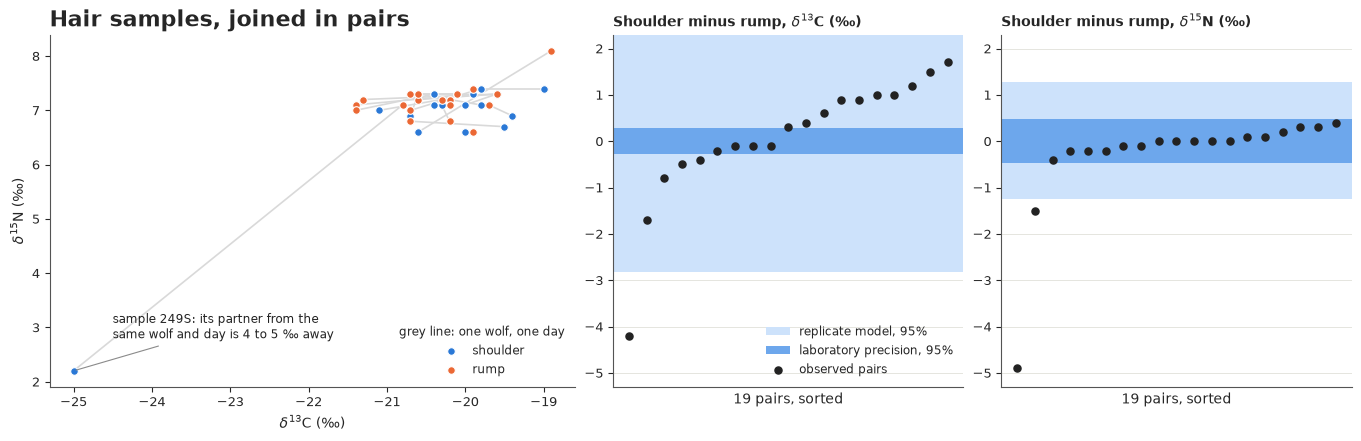

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axes[0]
for _, g in trial.groupby("pair"):
    ax.plot(g["d13C"], g["d15N"], color=LIGHT, lw=1.2, zorder=1)
for site, colour in (("shoulder", BLUE), ("rump", ORANGE)):
    g = trial[trial["site"] == site]
    ax.scatter(g["d13C"], g["d15N"], s=30, color=colour, ec="white", lw=0.8, label=site, zorder=2)
odd = trial.loc[trial["d15N"].idxmin()]
ax.annotate(f"sample {odd['sample_id']}: its partner from the\nsame wolf and day is 4 to 5 ‰ away",
            (odd["d13C"], odd["d15N"]), (odd["d13C"] + 0.5, odd["d15N"] + 0.6), fontsize=8.5, color=INK,
            arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax.set_xlabel(ISO_LABEL["d13C"])
ax.set_ylabel(ISO_LABEL["d15N"])
ax.legend(frameon=False, fontsize=8.5, loc="lower right", title="grey line: one wolf, one day", title_fontsize=8.5)
ax.set_title("Hair samples, joined in pairs", loc="left")
tidy(ax, grid=None)
for ax, iso, k in ((axes[1], "d13C", 0), (axes[2], "d15N", 1)):
    d = np.sort(pair_diff[iso].to_numpy())
    ax.axhspan(*band_t[:, k], color="#cde2fb", lw=0, label="replicate model, 95%")
    ax.axhspan(-1.96 * np.sqrt(2) * LAB_SD[k], 1.96 * np.sqrt(2) * LAB_SD[k], color="#6da7ec", lw=0,
               label="laboratory precision, 95%")
    ax.scatter(np.arange(len(d)), d, s=26, color=INK, zorder=3, label="observed pairs")
    ax.set_ylim(-5.3, 2.3)
    ax.set_xticks([])
    ax.set_xlabel("19 pairs, sorted")
    ax.set_title(f"Shoulder minus rump, {ISO_LABEL[iso]}", loc="left", fontsize=10)
    tidy(ax)
axes[1].legend(frameon=False, fontsize=8.5, loc="lower right");

On the left, each grey line joins the two samples of one wolf on one day. On the right, the dark band is
what the laboratory's precision allows for a shoulder-minus-rump difference, and the dots are the 19
differences observed.

**The laboratory's precision fails the check it invites.** Fifteen carbon pairs lie outside its band.
Forced to explain scatter it has no room for, the model inflates the spread between wolves, and it is
the one fit in this notebook that samples with visible effort (an r_hat near 1.02).

**Normal noise fails for nitrogen.** With the scale free, the model learns a within-wolf standard
deviation of about 0.9‰ for both isotopes. For nitrogen that is three to four times what 17 of the 19
pairs show: one sample has set the scale for all the others. It is sample 249S, from the shoulder of
wolf 487 in May, with values of -25.0 and 2.2 where the rump sample of the same day reads -20.8 and 7.1.
Those values would be unremarkable for a beaver, as part 2 will show, and we cannot know what happened.
The normal model takes the sample at face value: the pack's $\delta^{15}$N drops from 7.14 to 7.00 and
its uncertainty triples.

**The replicate model lets the odd sample be odd.** It estimates between two and three degrees of
freedom, a within-wolf standard deviation of 0.47‰ for carbon and 0.19‰ for nitrogen, and a pack mean of
-20.24 ± 0.14 and 7.14 ± 0.05. The spread between wolves is small and poorly determined, about 0.25‰ in
carbon. The next parts rely on that: these ten animals look like one consumer measured many times, and
the pack mean is the datum that carries the diet.

> **The choice.** The pack's hair value comes from a hierarchical model of replicate samples with
> Student-t noise, passed on as a mean and a covariance. *Rejected:* the laboratory's precision as the
> measurement error (15 of 19 carbon pairs outside its 95% band), and normal noise (one sample sets the
> nitrogen scale and moves the mean by 0.14‰). *Considered:* deleting the odd pair by hand, which gives
> nearly the same mean and leaves the next odd sample to the analyst's judgement; one rump sample per
> wolf, the article's choice, which discards what the pairs say about noise. *What would change our
> mind:* reference materials run with the samples, which would separate what the instrument adds from
> what the hair varies by.

## 2 · Prey: which ellipse belongs in the model?

The second link is the food. The trial took muscle from 20 of the deer, 13 of the beavers and 15 of the
geese that were fed. Each value is one animal.

In [7]:
data.describe("e123_prey_tissue")
prey = data.load("e123_prey_tissue")
muscle = prey[prey["tissue"] == "muscle"].reset_index(drop=True)
stats_ = muscle.groupby("species")[ISO].agg(["count", "mean", "std"]).reindex(PREY)
for iso in ISO:
    stats_[(iso, "se of mean")] = stats_[(iso, "std")] / np.sqrt(stats_[(iso, "count")])
print("\n" + stats_.sort_index(axis=1).round(2).to_string())

M_ALL = np.array([muscle.loc[muscle["species"] == s, ISO].mean().to_numpy() for s in PREY])
ANIMAL_VAR = np.array([muscle.loc[muscle["species"] == s, ISO].var().to_numpy() for s in PREY])
N_PREY = np.array([(muscle["species"] == s).sum() for s in PREY])
S_ALL = np.diag((ANIMAL_VAR / N_PREY[:, None]).ravel())       # uncertainty of the means (deer C, deer N, ...)

both = prey[prey["species"] == "deer"].pivot(index="animal", columns="tissue", values=ISO).dropna()
for iso in ISO:
    d = both[iso]["hair"] - both[iso]["muscle"]
    print(f"deer hair minus deer muscle, {iso}: {d.mean():+.2f} (se {d.std() / np.sqrt(len(d)):.2f}, n = {len(d)})")

wolf_means = trial.groupby("wolf")[ISO].median()
between = az.extract(hair_fit["idata"], var_names=["between"]).transpose("sample", "iso").to_numpy()
print("\nspread between wolves, permil (d13C, d15N):")
for share in (0.5, 0.9):
    p = np.array([share, (1 - share) / 2, (1 - share) / 2])
    print(f"  predicted if each wolf ate its own animals, diet {share:.0%} deer:",
          np.sqrt(p**2 @ ANIMAL_VAR).round(2))
print("  estimated in part 1 (posterior median and 95% upper bound):", np.median(between, 0).round(2),
      np.quantile(between, 0.95, 0).round(2))

e123_prey_tissue: One row per tissue sample of a food item (71 rows): animal (the item's label: D deer, B beaver, G goose), species, tissue (muscle for 20 deer, 13 beaver and 15 geese; hair for 23 deer), date in the workbook's sample_date column, d13C and d15N in permil.
  source: Same source and licence as e123_wolf_hair (Derbridge et al. 2015, PLoS ONE 10(3): e0119940, CC BY 4.0). DERIVED by tools/build_e123_wolf_trial.py from the sheets 'Muscle' and 'Hair'; the three deer whose muscle value is NA are dropped from the muscle rows (md5 80834db3be05e70220c0b6a41f2c8962). Measured values; their means and SDs reproduce Table 1 of the article.
  url:    https://journals.plos.org/plosone/article/file?type=supplementary&id=10.1371/journal.pone.0119940.s001

         d13C                          d15N                       
        count   mean se of mean   std count  mean se of mean   std
species                                                           
deer       20 -22.12       0.52  2.3

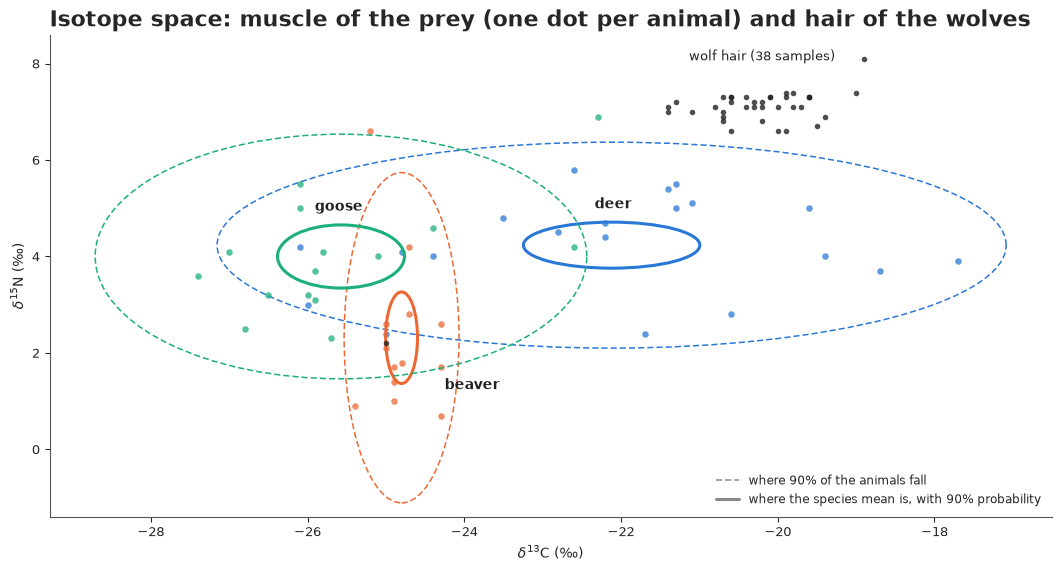

In [8]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))
for k, s in enumerate(PREY):
    g = muscle[muscle["species"] == s]
    ax.scatter(g["d13C"], g["d15N"], s=22, color=PREY_COLOUR[s], alpha=0.75, lw=0)
    region(ax, M_ALL[k], np.diag(ANIMAL_VAR[k]), PREY_COLOUR[s], lw=1.1, ls=(0, (4, 2)))
    region(ax, M_ALL[k], S_ALL[2 * k:2 * k + 2, 2 * k:2 * k + 2], PREY_COLOUR[s], lw=2.2)
ax.scatter(trial["d13C"], trial["d15N"], s=16, color=INK, lw=0, alpha=0.8)
ax.text(-20.2, 8.15, "wolf hair (38 samples)", fontsize=9, color=INK, ha="center", va="center")
ax.text(-22.1, 5.0, "deer", fontsize=10, color=INK, fontweight="bold", ha="center")
ax.text(-24.25, 1.25, "beaver", fontsize=10, color=INK, fontweight="bold", ha="left")
ax.text(-25.6, 4.95, "goose", fontsize=10, color=INK, fontweight="bold", ha="center")
ax.set_ylim(-1.4, 8.6)
ax.plot([], [], color=MUTED, lw=1.1, ls=(0, (4, 2)), label="where 90% of the animals fall")
ax.plot([], [], color=MUTED, lw=2.2, label="where the species mean is, with 90% probability")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_xlabel(ISO_LABEL["d13C"])
ax.set_ylabel(ISO_LABEL["d15N"])
ax.set_title("Isotope space: muscle of the prey (one dot per animal) and hair of the wolves", loc="left")
tidy(ax, grid=None);

Each species gets two ellipses, and choosing between them is the decision of this part. The dashed
ellipse is where the animals are: a deer can have a $\delta^{13}$C anywhere from -26 to -18‰. The solid
ellipse is where the species mean is, given the animals sampled. It is narrower by the square root of
the sample size.

The classical mixing models put the dashed ellipse into the likelihood. In the formulation the article
uses, the variance of a wolf's hair is $\sum_k p_k^2\,\omega_k^2 + \sigma^2$, with $\omega_k$ the
standard deviation among animals of prey $k$. Read as a story, each wolf builds its hair from its own
draw of prey animals. The story makes a prediction that can be tested without knowing the diet: wolves
on a diet of half deer would differ from one another by about 1.2‰ in $\delta^{13}$C, and wolves on nine
tenths deer by 2.1‰. Part 1 estimated that spread at about 0.25‰, and below about 0.5‰ with 95%
probability.

The wolves are several times more alike than the story allows. A wolf does not live a summer on one
deer: each of these ate from many carcasses, and the ten ate from the same ones. A hair that averages
many deer sits at the mean of those deer. What the model does not know is where that mean is, and this
ignorance is shared by all ten wolves and does not shrink when more wolves are sampled. That is the
solid ellipse.

For now we take its simplest version: for each species, the mean of the sampled animals with its
standard error, the 20 deer treated as interchangeable. Part 4 will send us back here. (The article
found no significant difference between hair and muscle of the same deer, and used muscle. So do we.)

> **The choice.** A prey signature is the mean of what the wolves ate, known up to the uncertainty of
> that mean. *Rejected:* the spread among individual animals as the wolves' own variance (it predicts
> wolves 1.2 to 2.1‰ apart in carbon; they are about 0.25 apart). *Considered:* deer hair as part of the
> deer signature, which needs numbers on what a wolf digests. *What would change our mind:* wolves that
> hunt alone and eat a handful of large animals in a season. Each would have its own draw, and the truth
> would lie between the two ellipses.

## 3 · From food to hair: the discrimination factor

Hair is not food. The body keeps a little more of the heavy isotope than it excretes, so a consumer's
tissue sits above its diet, by a few permil in nitrogen and by less in carbon. This shift $\Delta$ is
the discrimination factor. It has to come from somewhere other than the animals under study: a mixing
model cannot learn the diet and the shift from the same hair.

In [9]:
FOX, FOX_COV = np.array([2.6, 3.4]), np.diag([0.282**2, 0.204**2])   # red fox, as quoted by Derbridge et al.
NO_COV = np.zeros((2, 2))


def inside_triangle(point, tri):
    """Is the point inside the triangle of the three sources (barycentric test)?"""
    a, b, c = tri
    v0, v1, v2 = c - a, b - a, point - a
    den = v0[0] * v1[1] - v1[0] * v0[1]
    u = (v2[0] * v1[1] - v1[0] * v2[1]) / den
    v = (v0[0] * v2[1] - v2[0] * v0[1]) / den
    return (u >= 0) & (v >= 0) & (u + v <= 1)


def share_inside(shift, shift_cov, n_draws=4000, seed=RANDOM_SEED):
    """How often the hair, moved back by the shift, falls inside the triangle of prey means."""
    gen = np.random.default_rng(seed)
    src = gen.multivariate_normal(M_ALL.ravel(), S_ALL, n_draws).reshape(-1, 3, 2)
    food = gen.multivariate_normal(H, VH, n_draws) - gen.multivariate_normal(shift, shift_cov, n_draws)
    return np.mean([inside_triangle(f, t) for f, t in zip(food, src)])


print("hair of the pack:", H.round(2), "| prey means:", {s: M_ALL[k].round(2).tolist() for k, s in enumerate(PREY)})
print(f"highest d15N among the prey means: {M_ALL[:, 1].max():.2f}; hair: {H[1]:.2f}")
print(f"hair inside the triangle of prey, no shift: {share_inside(np.zeros(2), NO_COV):.0%} of draws; "
      f"with the fox shift: {share_inside(FOX, FOX_COV):.0%}")
food_fox = H - FOX
solve = np.linalg.solve(np.vstack([M_ALL.T, np.ones(3)]), np.append(food_fox, 1.0))
print("diet that reproduces the hair exactly, fox shift and prey means taken as known:", shares(solve, 2))

hair of the pack: [-20.24   7.14] | prey means: {'deer': [-22.12, 4.24], 'beaver': [-24.8, 2.32], 'goose': [-25.57, 4.0]}
highest d15N among the prey means: 4.24; hair: 7.14
hair inside the triangle of prey, no shift: 0% of draws; with the fox shift: 45%
diet that reproduces the hair exactly, fox shift and prey means taken as known: {'deer': 0.74, 'beaver': 0.25, 'goose': 0.01}


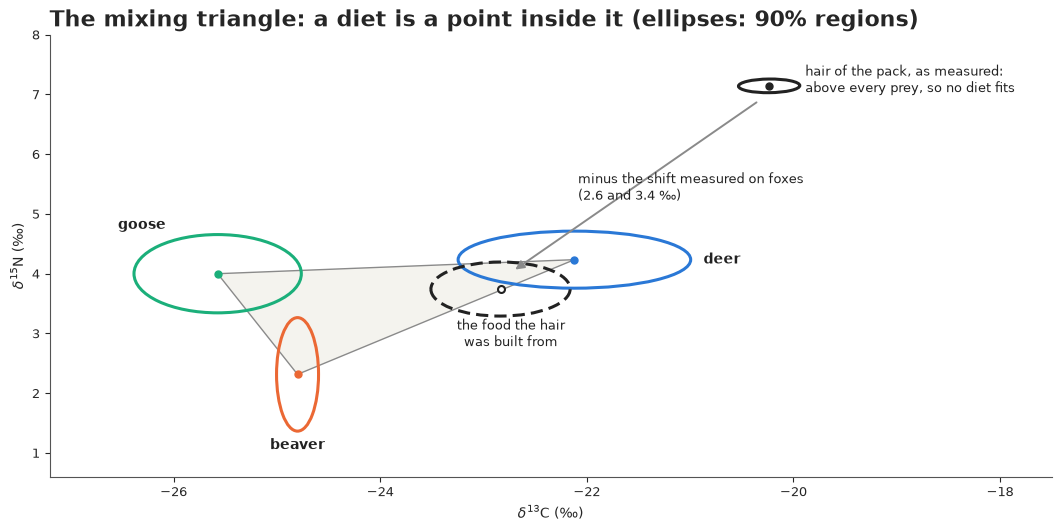

In [10]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.fill(M_ALL[:, 0], M_ALL[:, 1], color="#f4f3ee", ec=MUTED, lw=1.0, zorder=0)
for k, s in enumerate(PREY):
    region(ax, M_ALL[k], S_ALL[2 * k:2 * k + 2, 2 * k:2 * k + 2], PREY_COLOUR[s], lw=2.2)
    ax.plot(*M_ALL[k], "o", ms=5, color=PREY_COLOUR[s])
ax.text(M_ALL[0, 0] + 1.25, M_ALL[0, 1], "deer", fontsize=10, fontweight="bold", color=INK, va="center")
ax.text(M_ALL[1, 0], M_ALL[1, 1] - 1.25, "beaver", fontsize=10, fontweight="bold", color=INK, ha="center")
ax.text(M_ALL[2, 0] - 0.5, M_ALL[2, 1] + 0.75, "goose", fontsize=10, fontweight="bold", color=INK, ha="right")
region(ax, H, VH, INK, lw=2.2)
ax.plot(*H, "o", ms=5, color=INK)
ax.text(H[0] + 0.35, H[1] + 0.1, "hair of the pack, as measured:\nabove every prey, so no diet fits",
        fontsize=9, color=INK, va="center")
region(ax, food_fox, VH + FOX_COV, INK, lw=2.2, ls=(0, (4, 2)))
ax.plot(*food_fox, "o", ms=5, color="white", mec=INK, mew=1.5)
ax.add_patch(FancyArrowPatch(H - [0.1, 0.25], food_fox + [0.12, 0.3], arrowstyle="-|>", mutation_scale=13,
                             color=MUTED, lw=1.4))
ax.text(food_fox[0] + 0.75, food_fox[1] + 1.7, "minus the shift measured on foxes\n(2.6 and 3.4 ‰)",
        fontsize=9, color=INK, va="center")
ax.text(food_fox[0] + 0.1, food_fox[1] - 0.75, "the food the hair\nwas built from", fontsize=9, color=INK,
        va="center", ha="center")
ax.set_xlim(-27.2, -17.5)
ax.set_ylim(0.6, 8.0)
ax.set_xlabel(ISO_LABEL["d13C"])
ax.set_ylabel(ISO_LABEL["d15N"])
ax.set_title("The mixing triangle: a diet is a point inside it (ellipses: 90% regions)", loc="left")
tidy(ax, grid=None);

**No shift fails at once.** The pack's hair has a $\delta^{15}$N of 7.1‰, and the highest prey mean is
4.2. A mixture is a weighted average, and no average of numbers below 4.3 gives 7.1. In none of 4,000
draws of the prey means and the hair does the hair fall inside the triangle of the prey. This check is
worth running before any model (the MixSIAR workflow lists plotting the data among its checks before a
model is run): a consumer outside the polygon of its sources means a missing prey, a wrong shift, or
both.

**A borrowed shift.** The article presents its discrimination factors as the first measured
experimentally for gray wolves. Until then, studies of wolves commonly used values measured on captive
red foxes by Roth and Hobson (2000), which the article quotes as 2.6‰ for carbon and 3.4‰ for nitrogen,
with standard deviations of 0.28 and 0.20. A field biologist is in that position with any species nobody
has kept in a pen. We take the fox values, with their standard deviations as our uncertainty. Moved back
by that much, the hair lands at the edge of the triangle between deer and beaver, close to deer, and
inside it in a little under half of the draws.

If the prey means and the shift were known exactly, two equations and the constraint that shares add to
one would give a single diet: 74% deer, 25% beaver, 1% goose. The rest of the notebook is about how far
that tidy answer can be trusted.

> **The choice.** The fox values, with the standard deviations reported with them. *Rejected:* no shift
> (hair outside the triangle in every draw). *Considered:* the fox values as exact, which their own
> standard deviations contradict; a wider uncertainty for the step from fox to wolf, for which we have
> no number that is not a guess. *What would change our mind:* a discrimination factor measured on
> wolves. This dataset contains one, and part 6 uses it; until the feeding record is opened we behave as
> if it did not.

## 4 · The diet: a Dirichlet mixing model

We now have the three inputs as distributions: the pack's hair $h$ with covariance $V_h$ (part 1), the
prey signatures $\mu_k$ with their uncertainty (part 2), and the shift $\Delta$ with its uncertainty
(part 3). The mixing model ties them together:

$$h \sim \mathcal{N}\Big(\sum_k p_k\,\mu_k + \Delta,\; V_h\Big), \qquad \mu_k \sim \mathcal{N}(m_k, S_k), \qquad \Delta \sim \mathcal{N}(d, D),$$

with a prior on the shares $p$. The prey signatures and the shift are nuisance parameters: unknown, not
of interest, and impossible to ignore.

Two things make this model tractable. The diet has two free dimensions, so every possible diet can be
laid out on a grid over a triangle. And for a fixed diet the model is linear in the nuisance parameters,
all of them normal, so they integrate out by hand: given $p$, the hair is normal with mean $\sum_k p_k
m_k + d$ and covariance $\sum_k p_k^2 S_k + D + V_h$. The posterior over the grid is exact up to its
step of half a percent. We use it for the pictures and for the refits of parts 7 and 8, and we also fit
the full model with NUTS, nuisance parameters included, to check the algebra.

A diet of three prey is a point in an equilateral triangle: each corner is a diet of one prey only, and
the distance from the opposite side is that prey's share. (E70 builds this ternary plot step by step.)

In [11]:
SQ3 = np.sqrt(3) / 2


def make_grid(n):
    """Every diet of three prey in steps of 1/n, with the log density of three priors."""
    i, j = np.meshgrid(np.arange(n + 1), np.arange(n + 1), indexing="ij")
    keep = i + j <= n
    idx = np.stack([i[keep], j[keep], n - i[keep] - j[keep]], 1)       # deer, beaver, goose
    P = idx / n
    safe = np.clip(P, 0.5 / n, None)
    prior = {"flat on the question": -np.log(np.clip(1 - P[:, 0], 0.5 / n, None)),   # deer ~ U, split ~ U
             "flat Dirichlet": np.zeros(len(P)),
             "informative": 12 * np.log(safe[:, 0])}                                  # Dirichlet(13, 1, 1)
    x, y = P[:, 2] + 0.5 * P[:, 0], SQ3 * P[:, 0]
    return {"n": n, "P": P, "idx": idx, "prior": prior, "tri": mtri.Triangulation(x, y)}


def normalise(logw):
    w = np.exp(logw - logw.max())
    return w / w.sum()


def diet_posterior(G, h, Vh, M, S, shift, shift_cov, prior="flat on the question", tracers=None):
    """Exact posterior over the grid of diets. Prey means (M, covariance S) and the shift are normal, so
    they integrate out: given the diet p, hair ~ N(p M + shift, A S A' + shift_cov + Vh)."""
    P, T = G["P"], M.shape[1]
    A = np.zeros((len(P), T, 3 * T))
    for k in range(3):
        for t in range(T):
            A[:, t, k * T + t] = P[:, k]
    mean = P @ M + shift
    var = A @ S @ A.transpose(0, 2, 1) + shift_cov + Vh
    if tracers is not None:
        mean, var = mean[:, tracers], var[:, tracers][:, :, tracers]
        h = h[tracers]
    r = h - mean
    loglik = -0.5 * np.einsum("na,nab,nb->n", r, np.linalg.inv(var), r) - 0.5 * np.log(np.linalg.det(var))
    return normalise(loglik + G["prior"][prior])


def quantiles(w, x, probs=(0.05, 0.5, 0.95)):
    order = np.argsort(x, kind="stable")
    cum = np.cumsum(w[order])
    return np.array([x[order][min(np.searchsorted(cum, pr), len(x) - 1)] for pr in probs])


def describe_diet(G, w, label):
    P = G["P"]
    parts = [("deer", P[:, 0]), ("beaver", P[:, 1]), ("goose", P[:, 2]), ("small prey", 1 - P[:, 0])]
    cells = []
    for name, x in parts:
        lo, mid, hi = quantiles(w, x)
        cells.append(f"{name} {mid:.2f} ({lo:.2f} to {hi:.2f})")
    cov = np.cov(P[:, 1], P[:, 2], aweights=w)
    corr = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    print(f"{label:<34}" + " | ".join(cells) + f" | corr(beaver, goose) {corr:+.2f}")


def marginal(G, w, x_index):
    """Density of one share (or of small prey, x_index = None) on the grid's steps."""
    n = G["n"]
    k = G["idx"][:, x_index] if x_index is not None else n - G["idx"][:, 0]
    return np.arange(n + 1) / n, np.bincount(k, weights=w, minlength=n + 1) * n


def ternary(ax, title=None, labels=True):
    """An equilateral triangle for diets: deer on top, beaver bottom left, goose bottom right."""
    ax.plot([0, 1, 0.5, 0], [0, 0, SQ3, 0], color=INK, lw=1.0, zorder=4)
    for g in (0.2, 0.4, 0.6, 0.8):
        for a, b in (((g, 1 - g, 0), (g, 0, 1 - g)), ((1 - g, g, 0), (0, g, 1 - g)), ((1 - g, 0, g), (0, 1 - g, g))):
            a, b = np.array(a), np.array(b)
            ax.plot([a[2] + 0.5 * a[0], b[2] + 0.5 * b[0]], [SQ3 * a[0], SQ3 * b[0]], color=GRID, lw=0.6, zorder=3)
        if labels:
            ax.text(0.5 * g - 0.03, SQ3 * g, f"{g:.0%}", fontsize=7.5, color=MUTED, ha="right", va="center")
    ax.text(0.5, SQ3 + 0.03, "deer", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=INK)
    ax.text(-0.02, -0.03, "beaver", ha="center", va="top", fontsize=9.5, fontweight="bold", color=INK)
    ax.text(1.02, -0.03, "goose", ha="center", va="top", fontsize=9.5, fontweight="bold", color=INK)
    ax.set_aspect("equal")
    ax.set_xlim(-0.13, 1.13)
    ax.set_ylim(-0.12, SQ3 + 0.12)
    ax.axis("off")
    if title:
        ax.set_title(title, loc="left", fontsize=10)


def ternary_density(ax, G, w, masses=(0.95, 0.8, 0.5)):
    """Shade the smallest regions of the triangle that hold 95%, 80% and 50% of the probability."""
    order = np.argsort(w)[::-1]
    cum = np.cumsum(w[order])
    levels = [w[order][min(np.searchsorted(cum, m), len(w) - 1)] for m in masses] + [w.max() * 1.001]
    ax.tricontourf(G["tri"], w, levels=levels, colors=[SEQ(0.25), SEQ(0.5), SEQ(0.8)], zorder=1)


def ternary_point(ax, p, **kw):
    ax.plot(p[2] + 0.5 * p[0], SQ3 * p[0], **{"marker": "*", "ms": 13, "color": ORANGE, "mec": "white",
                                              "mew": 0.8, "ls": "none", "zorder": 6, **kw})


G = make_grid(200)
print(f"{len(G['P']):,} diets on the grid")

20,301 diets on the grid


### A flat prior that is not flat

The usual prior for shares is the Dirichlet with all its parameters equal to one. It is uniform over the
triangle and is called uninformative. Before using it we look at what it says about the quantity a wolf
biologist asks about first: how much of the diet is deer.

flat Dirichlet on three prey: P(deer > 0.9) = 0.010; prior median of the small-prey share: 0.71
flat Dirichlet on four prey (hare added): P(deer > 0.9) = 0.0009
flat on the question: P(deer > 0.9) = 0.100 by construction


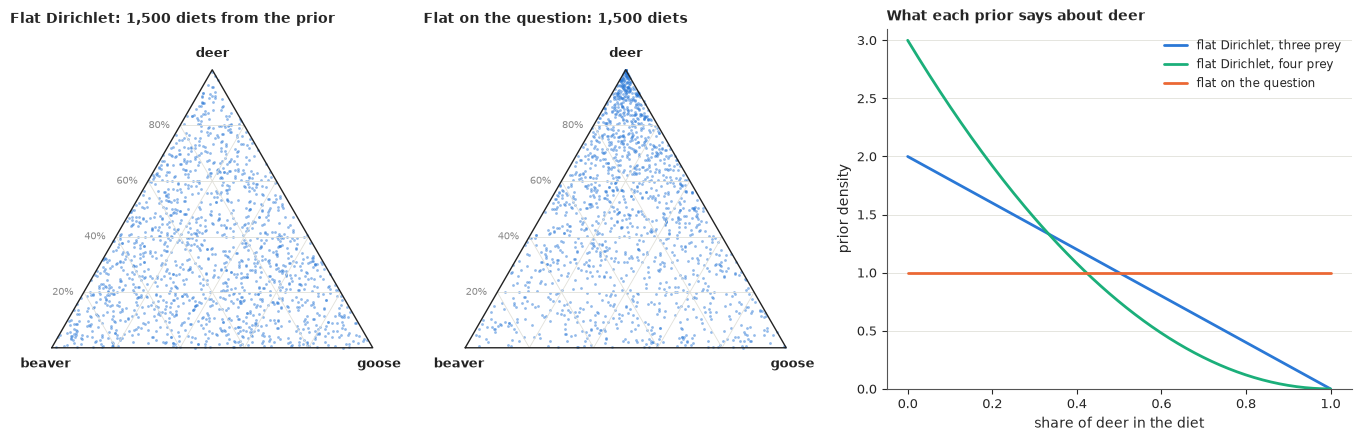

In [12]:
gen = np.random.default_rng(RANDOM_SEED)
flat3 = gen.dirichlet(np.ones(3), 1500)
deer_u, split_u = gen.random(1500), gen.random(1500)
nested = np.stack([deer_u, (1 - deer_u) * split_u, (1 - deer_u) * (1 - split_u)], 1)
many3, many4 = gen.dirichlet(np.ones(3), 200_000)[:, 0], gen.dirichlet(np.ones(4), 200_000)[:, 0]
print(f"flat Dirichlet on three prey: P(deer > 0.9) = {(many3 > 0.9).mean():.3f}; "
      f"prior median of the small-prey share: {np.median(1 - many3):.2f}")
print(f"flat Dirichlet on four prey (hare added): P(deer > 0.9) = {(many4 > 0.9).mean():.4f}")
print("flat on the question: P(deer > 0.9) = 0.100 by construction")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for ax, draws, title in ((axes[0], flat3, "Flat Dirichlet: 1,500 diets from the prior"),
                         (axes[1], nested, "Flat on the question: 1,500 diets")):
    ternary(ax, title)
    ax.scatter(draws[:, 2] + 0.5 * draws[:, 0], SQ3 * draws[:, 0], s=4, color=BLUE, alpha=0.5, lw=0, zorder=2)
ax = axes[2]
xs = np.linspace(0, 1, 200)
ax.plot(xs, 2 * (1 - xs), color=BLUE, lw=2, label="flat Dirichlet, three prey")
ax.plot(xs, 3 * (1 - xs) ** 2, color=AQUA, lw=2, label="flat Dirichlet, four prey")
ax.plot(xs, np.ones_like(xs), color=ORANGE, lw=2, label="flat on the question")
ax.set_xlabel("share of deer in the diet")
ax.set_ylabel("prior density")
ax.set_ylim(0, 3.1)
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("What each prior says about deer", loc="left", fontsize=10)
tidy(ax);

A prior that is uniform over the triangle is far from uniform about deer. With three prey, its density
for the deer share falls in a straight line from 2 at zero to 0 at one. It puts the chance of a diet of
more than 90% deer at 1 in 100, and its median for the two small prey together is 71%. Worse, what it
says about deer depends on how finely the other prey are listed. Add snowshoe hare as a fourth source
and the same "uninformative" prior makes a deer specialist ten times less likely again, although nothing
has been learned about deer.

A prior that is flat on the question takes two questions one at a time and is uniform on each: what
share is deer, and how the rest divides between beaver and goose. Listing more small prey would leave
its statement about deer untouched. On the triangle it piles diets up towards the deer corner, which
looks like an opinion and is the absence of one about deer. We choose it here, before any hair has been
compared with any prey, and keep the flat Dirichlet as a rival to the end.

### First pass, and a way back

With all 20 deer treated alike (part 2), the fox shift (part 3) and this prior, the grid gives a first
answer. The natural attack on it is aimed at the deer. Hair grows in summer and autumn: the article
takes the growth period to end on 31 October. Of the 20 deer sampled, only five were sampled within it,
four in June and one on the last day of October; the others were fed in November, December and the
following May. If deer change with the season, those five are the right sample and the other fifteen are
the wrong animals.

In [13]:
w_first = diet_posterior(G, H, VH, M_ALL, S_ALL, FOX, FOX_COV)
describe_diet(G, w_first, "all 20 deer, alike")

window = muscle[(muscle["species"] == "deer") & (muscle["date"] <= "2011-10-31")]
M_WIN, S_WIN = M_ALL.copy(), S_ALL.copy()
M_WIN[0] = window[ISO].mean().to_numpy()
S_WIN[:2, :2] = np.diag(window[ISO].var().to_numpy() / len(window))
w_window = diet_posterior(G, H, VH, M_WIN, S_WIN, FOX, FOX_COV)
describe_diet(G, w_window, f"the {len(window)} deer of June to October")
print("\ndeer muscle by month of sampling:")
print(muscle[muscle["species"] == "deer"].assign(month=lambda d: d["date"].str[:7]).groupby("month")[ISO]
      .agg(["count", "mean"]).round(2).T.to_string())
print(f"deer signature, all 20: {M_ALL[0].round(2)}; the {len(window)} of summer: {M_WIN[0].round(2)}")

all 20 deer, alike                deer 0.72 (0.53 to 0.94) | beaver 0.15 (0.01 to 0.35) | goose 0.09 (0.01 to 0.29) | small prey 0.28 (0.06 to 0.47) | corr(beaver, goose) -0.25
the 5 deer of June to October     deer 0.50 (0.38 to 0.65) | beaver 0.33 (0.11 to 0.51) | goose 0.16 (0.01 to 0.40) | small prey 0.50 (0.35 to 0.62) | corr(beaver, goose) -0.76

deer muscle by month of sampling:
month       2011-06  2011-10  2011-11  2011-12  2012-05
d13C count     4.00      1.0     4.00     4.00     7.00
     mean    -20.62    -21.1   -23.42   -22.52   -22.14
d15N count     4.00      1.0     4.00     4.00     7.00
     mean      4.68      5.1     3.32     4.25     4.37
deer signature, all 20: [-22.12   4.24]; the 5 of summer: [-20.72   4.76]


The answer moves from 72% deer (53 to 94) to 50% (38 to 65). Two defensible definitions of "the deer the
wolves ate" give intervals that barely overlap. The five summer deer are richer in $^{13}$C than the
twenty together by 1.4‰, which moves the deer corner of the triangle away from the hair, and the model
fills the gap with beaver.

This is the first orange arrow of the route map. Pooling all 20 assumes that the month does not matter
at all. Keeping five assumes that it matters completely, and that five animals pin down a summer. The
monthly means cannot settle it: June deer average -20.6‰ and November deer -23.4, but with four animals
each and a spread among deer of 2.3‰, differences of that size turn up by chance.

### Back to the prey: batches, partly pooled

A hierarchical model replaces the choice by an estimate. Animals of one species sampled in the same
month form a batch. Each batch has its own mean, drawn around the species mean with a standard deviation
$\tau$ estimated from the data: one $\tau$ per isotope, shared by the three species, because nine
batches are too few to estimate it for each.

$$y_i \sim \mathcal{N}\big(\mu_{s(i)} + b_{\mathrm{batch}(i)},\ \sigma_{s(i)}\big), \qquad b \sim \mathcal{N}(0, \tau).$$

If the batches are alike, $\tau$ is small and the model pools them; if they differ, it keeps them apart.
The signature that goes to the mixing model is then built, for each species, from what the wolves ate
while the hair grew. For deer that is five monthly batches from June to October: two were sampled (June,
and October through its single animal), and the three that were not are drawn from the same distribution
of batch effects. For geese it is the two batches sampled, and for beaver the animals sampled, 12 of the
13 in August.

In [14]:
muscle["batch"] = muscle["species"] + " " + muscle["date"].str[:7]
BATCHES = sorted(muscle["batch"].unique())
UNSAMPLED = ["deer 2011-07", "deer 2011-08", "deer 2011-09"]      # months of the hair's growth with no deer sampled
s_idx = pd.Index(PREY).get_indexer(muscle["species"])
b_idx = pd.Index(BATCHES).get_indexer(muscle["batch"])
at = {b: i for i, b in enumerate(BATCHES)}

with pm.Model(coords={"iso": ISO, "species": PREY, "batch": BATCHES, "unsampled": UNSAMPLED}) as source_model:
    mu = pm.Normal("mu", [-23.0, 4.0], 5.0, dims=("species", "iso"))            # long-run mean of a species
    sigma = pm.HalfNormal("sigma", 2.0, dims=("species", "iso"))                # animal to animal
    tau = pm.HalfNormal("tau", 1.0, dims="iso")                                 # batch to batch, shared
    z_batch = pm.Normal("z_batch", 0.0, 1.0, dims=("batch", "iso"))
    z_new = pm.Normal("z_new", 0.0, 1.0, dims=("unsampled", "iso"))
    pm.Normal("y", mu[s_idx] + tau * z_batch[b_idx], sigma[s_idx], observed=muscle[ISO].to_numpy())
    # what the wolves ate while the hair grew: five months of deer, the two goose batches, the beavers
    deer = mu[0] + tau * (z_batch[at["deer 2011-06"]] + z_batch[at["deer 2011-10"]] + z_new.sum(0)) / 5
    beaver = mu[1] + tau * (z_batch[at["beaver 2011-06"]] + 12 * z_batch[at["beaver 2011-08"]]) / 13
    goose = mu[2] + tau * (z_batch[at["goose 2011-06"]] + z_batch[at["goose 2011-07"]]) / 2
    pm.Deterministic("eaten", pt.stack([deer, beaver, goose]), dims=("species", "iso"))
    idata_src = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.99)
note("prey, batches partly pooled", idata_src)
print(pd.DataFrame(DIAG[-1:]).to_string(index=False))
print("\nbatches (species and month of sampling):")
print(muscle.groupby("batch")[ISO].agg(["count", "mean"]).round(2).T.to_string())
for var in ("tau", "eaten"):                      # one variable at a time: see the note on az.summary below
    print(az.summary(idata_src, var_names=[var], round_to=2)[["mean", "sd", "eti89_lb", "eti89_ub"]].to_string())
eaten = az.extract(idata_src, var_names=["eaten"]).transpose("sample", "species", "iso").to_numpy().reshape(-1, 6)
M_EAT, S_EAT = eaten.mean(0).reshape(3, 2), np.cov(eaten.T)
print("\nsd of the deer signature, permil (d13C, d15N): all deer alike", np.sqrt(np.diag(S_ALL)[:2]).round(2),
      "| summer deer only", np.sqrt(np.diag(S_WIN)[:2]).round(2), "| batches partly pooled",
      np.sqrt(np.diag(S_EAT)[:2]).round(2))

                      model  divergences  max r_hat  min ESS
prey, batches partly pooled            0      1.004      555

batches (species and month of sampling):
batch       beaver 2011-06  beaver 2011-08  deer 2011-06  deer 2011-10  deer 2011-11  deer 2011-12  deer 2012-05  goose 2011-06  goose 2011-07
d13C count             1.0           12.00          4.00           1.0          4.00          4.00          7.00           8.00           7.00
     mean            -25.2          -24.77        -20.62         -21.1        -23.42        -22.52        -22.14         -26.15         -24.91
d15N count             1.0           12.00          4.00           1.0          4.00          4.00          7.00           8.00           7.00
     mean              6.6            1.96          4.68           5.1          3.32          4.25          4.37           3.61           4.44
           mean    sd  eti89_lb  eti89_ub
tau[d13C]  0.49  0.37      0.05      1.18
tau[d15N]  0.84  0.46      0.15      

The batch standard deviation is about 0.5‰ for carbon, with an interval from almost nothing to 1.2: the
data cannot say whether deer change with the season, and the model reports exactly that. For nitrogen it
is larger, about 0.8‰, and one animal has much to do with it. The single beaver sampled in June has a
$\delta^{15}$N of 6.6, where the twelve of August average 2.0.

The deer signature that comes out, -22.0 and 4.4, is close to the mean of all 20 deer. Its uncertainty
is not: about 0.6‰ in carbon where pooling gave 0.52, and 0.5‰ in nitrogen where pooling gave 0.22. (We
summarise `tau` and `eaten` in separate calls: with ArviZ 1.3, one call for both printed the six values
of `eaten` under the wrong labels.)

Now the mixing model itself in PyMC, with the prey signatures and the shift as parameters. The prior
that is flat on the question is two uniform variables: the deer share, and the beaver's part of the
rest.

In [15]:
def fit_mixing(h, Vh, M, S, shift, shift_sd, prior="flat on the question"):
    """The mixing model with its nuisance parameters kept: prey signatures and the shift are sampled."""
    with pm.Model(coords={"species": PREY, "iso": ISO}):
        if prior == "flat on the question":
            deer_share = pm.Uniform("deer_share", 0.0, 1.0)
            split = pm.Uniform("split", 0.0, 1.0)                     # beaver's part of the small prey
            p = pm.Deterministic("p", pt.stack([deer_share, (1 - deer_share) * split,
                                                (1 - deer_share) * (1 - split)]), dims="species")
        else:
            p = pm.Dirichlet("p", np.ones(3), dims="species")
        src = pm.MvNormal("src", M.ravel(), cov=S, shape=6).reshape((3, 2))
        tdf = pm.Normal("shift", shift, shift_sd, dims="iso")
        pm.MvNormal("hair", pt.dot(p, src) + tdf, cov=Vh, observed=h)
        return pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.95)


idata_mix = fit_mixing(H, VH, M_EAT, S_EAT, FOX, np.sqrt(np.diag(FOX_COV)))
note("mixing, prior flat on the question", idata_mix)
idata_dir = fit_mixing(H, VH, M_EAT, S_EAT, FOX, np.sqrt(np.diag(FOX_COV)), prior="flat Dirichlet")
note("mixing, flat Dirichlet", idata_dir)
print(pd.DataFrame(DIAG[-2:]).to_string(index=False))

w_blind = diet_posterior(G, H, VH, M_EAT, S_EAT, FOX, FOX_COV)
w_dirichlet = diet_posterior(G, H, VH, M_EAT, S_EAT, FOX, FOX_COV, prior="flat Dirichlet")
p_draws = az.extract(idata_mix, var_names=["p"]).transpose("sample", "species").to_numpy()
p_dir = az.extract(idata_dir, var_names=["p"]).transpose("sample", "species").to_numpy()
print("\ndeer, beaver, goose: 5%, 50% and 95% points")
for label, draws, w in (("flat on the question", p_draws, w_blind), ("flat Dirichlet", p_dir, w_dirichlet)):
    print(f"  {label}, NUTS:", np.quantile(draws, [0.05, 0.5, 0.95], axis=0).T.round(2).tolist())
    print(f"  {label}, grid:", [quantiles(w, G["P"][:, k]).round(2).tolist() for k in range(3)])
print()
describe_diet(G, w_first, "all 20 deer, alike")
describe_diet(G, w_window, "summer deer only")
describe_diet(G, w_blind, "batches partly pooled (kept)")
describe_diet(G, w_dirichlet, "the same, flat Dirichlet")
print("shift between food and hair, prior and posterior:",
      az.summary(idata_mix, var_names=["shift"], round_to=2)[["mean", "sd"]].to_numpy().tolist())

                             model  divergences  max r_hat  min ESS
mixing, prior flat on the question            0      1.004     1067
            mixing, flat Dirichlet            0      1.003     1239

deer, beaver, goose: 5%, 50% and 95% points
  flat on the question, NUTS: [[0.48, 0.7, 0.94], [0.01, 0.15, 0.38], [0.01, 0.1, 0.33]]
  flat on the question, grid: [[0.5, 0.7, 0.95], [0.0, 0.15, 0.38], [0.0, 0.1, 0.32]]
  flat Dirichlet, NUTS: [[0.46, 0.64, 0.85], [0.03, 0.2, 0.41], [0.01, 0.13, 0.36]]
  flat Dirichlet, grid: [[0.46, 0.64, 0.84], [0.02, 0.2, 0.42], [0.01, 0.13, 0.36]]

all 20 deer, alike                deer 0.72 (0.53 to 0.94) | beaver 0.15 (0.01 to 0.35) | goose 0.09 (0.01 to 0.29) | small prey 0.28 (0.06 to 0.47) | corr(beaver, goose) -0.25
summer deer only                  deer 0.50 (0.38 to 0.65) | beaver 0.33 (0.11 to 0.51) | goose 0.16 (0.01 to 0.40) | small prey 0.50 (0.35 to 0.62) | corr(beaver, goose) -0.76
batches partly pooled (kept)      deer 0.70 (0.49 to 

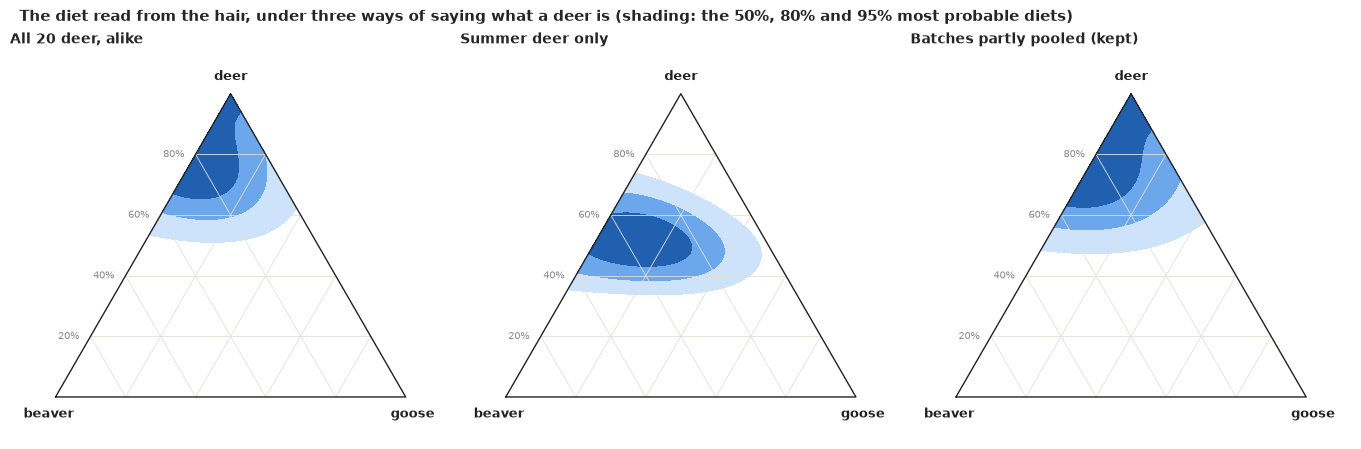

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5))
for ax, w, title in ((axes[0], w_first, "All 20 deer, alike"), (axes[1], w_window, "Summer deer only"),
                     (axes[2], w_blind, "Batches partly pooled (kept)")):
    ternary(ax, title)
    ternary_density(ax, G, w)
fig.suptitle("The diet read from the hair, under three ways of saying what a deer is "
             "(shading: the 50%, 80% and 95% most probable diets)", x=0.01, ha="left", fontsize=11);

beaver: median 0.15, 90% interval 0.01 to 0.39; P(share < 0.05) = 0.19
goose: median 0.10, 90% interval 0.01 to 0.33; P(share < 0.05) = 0.28
small prey: median 0.30, 90% interval 0.05 to 0.51; P(share < 0.05) = 0.05


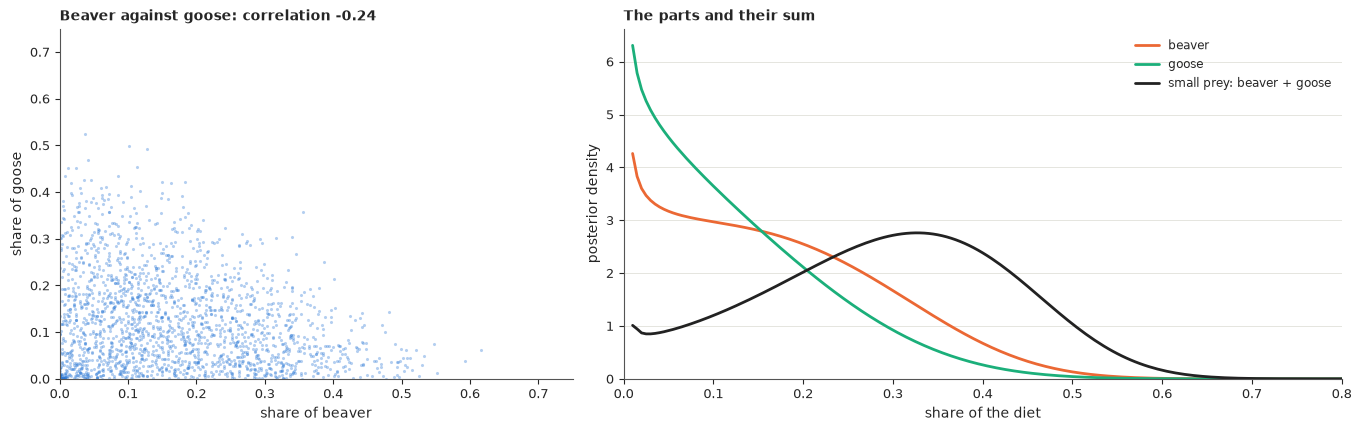

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
thin = p_draws[::2]
ax.scatter(thin[:, 1], thin[:, 2], s=5, color=BLUE, alpha=0.35, lw=0)
ax.set_xlim(0, 0.75)
ax.set_ylim(0, 0.75)
ax.set_xlabel("share of beaver")
ax.set_ylabel("share of goose")
ax.set_title(f"Beaver against goose: correlation {np.corrcoef(p_draws[:, 1], p_draws[:, 2])[0, 1]:+.2f}", loc="left",
             fontsize=10)
tidy(ax, grid=None)
ax = axes[1]
for x_index, colour, label in ((1, ORANGE, "beaver"), (2, AQUA, "goose"), (None, INK, "small prey: beaver + goose")):
    x, dens = marginal(G, w_blind, x_index)
    smooth = np.convolve(dens, np.ones(5) / 5, mode="same")
    ax.plot(x[2:-2], smooth[2:-2], color=colour, lw=2, label=label)
ax.set_xlim(0, 0.8)
ax.set_ylim(0, None)
ax.set_xlabel("share of the diet")
ax.set_ylabel("posterior density")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("The parts and their sum", loc="left", fontsize=10)
tidy(ax);
for name, x in (("beaver", G["P"][:, 1]), ("goose", G["P"][:, 2]), ("small prey", 1 - G["P"][:, 0])):
    lo, mid, hi = quantiles(w_blind, x)
    print(f"{name}: median {mid:.2f}, 90% interval {lo:.2f} to {hi:.2f}; "
          f"P(share < 0.05) = {w_blind[x < 0.05].sum():.2f}")

NUTS and the grid agree to within two hundredths on every quantile, for both priors, with no
divergences. The posterior of the shift is its prior: one pack mean cannot inform the diet and the shift
at once, which is why the shift has to be right before it goes in.

**The answer, before the record is opened.** Deer is about 70% of the diet, with a 90% interval from
about 50% to 95%. The hierarchical prey model lands near the pooled answer, a little wider, and far from
the summer-only one: the fork that looked largest was mostly five animals' worth of chance.

**Beaver and goose trade off, mildly.** The shaded region hangs from the deer corner along the edge that
leads to beaver, and spreads towards goose. The two shares are negatively correlated, at about -0.2, and
each is compatible with next to nothing and with a third of the diet: beaver 15% (1 to 39), goose 10% (1
to 33). Their sum is better behaved: the small prey together are 30% of the diet (5 to 51), with a clear
mode, because carbon separates deer from both of them at once. The sum is the complement of the deer
share, so merging estimates nothing new. What changes is what we decline to report.

How strong the trade-off is depends on where the hair falls. With summer deer only, where the model
wanted half the diet to be small prey, the correlation was -0.76, a real ridge. Near the deer corner
there is little small prey to trade.

> **The choice.** Shares of deer and of small prey, from a mixing model with a prior flat on those two
> questions, prey signatures from partly pooled batches, and nuisance parameters integrated over. Before
> the record: deer about 70% (50 to 95). *Rejected:* the flat Dirichlet (a prior chance of 1 in 100 for
> a deer specialist, and another if the list of prey is longer); all deer alike and summer deer only
> (the two ends of a question the data can only partly answer); beaver and goose reported apart.
> *Considered:* an informative prior from scats or prey abundance, which the article recommends. We have
> none that does not come from the feeding record. *What would change our mind:* prey sampled in every
> month the hair grew.

## 5 · The feeding record: what the wolves were given

Now the part that a field study never has. The workbook lists, for every wolf, every carcass that went
into its enclosure, with a date.

In [18]:
data.describe("e123_wolf_feeding")
feeding = data.load("e123_wolf_feeding")
feeding["date"] = pd.to_datetime(feeding["date"])
GROWTH_END = pd.Timestamp("2011-10-31")                        # the article's end of the hair-growth period
grown = feeding[feeding["date"] <= GROWTH_END]
items = grown.drop_duplicates("item").groupby("species").size().reindex(PREY)
per_wolf = grown.groupby(["wolf", "species"])["item"].nunique().unstack()[PREY]
print(f"\ncarcasses given to the ten wolves up to {GROWTH_END:%d %B %Y}:", items.to_dict())
print("per wolf, fewest and most:", per_wolf.min().to_dict(), per_wolf.max().to_dict())

KG = {"deer": (41, 223), "beaver": (5, 35), "goose": (3, 6)}  # carcass weights used in the article, kg
mid_kg = np.array([np.mean(KG[s]) for s in PREY])
by_count = (items / items.sum()).to_numpy()
TRUTH = (items.to_numpy() * mid_kg) / (items.to_numpy() * mid_kg).sum()
gen = np.random.default_rng(RANDOM_SEED)
kg_draws = np.stack([gen.uniform(*KG[s], 20_000) for s in PREY], 1) * items.to_numpy()
deer_band = np.quantile(kg_draws[:, 0] / kg_draws.sum(1), [0.05, 0.95])
print("diet by number of carcasses:", shares(by_count))
print("diet by weight, mid-range carcass weights:", shares(TRUTH),
      "| the article: deer 0.941, beaver 0.020, goose 0.039")
print(f"deer share if each species' average carcass weight lies anywhere in its range: {deer_band[0]:.2f} to "
      f"{deer_band[1]:.2f} (90%)")

e123_wolf_feeding: One row per wolf and food item (3,010 rows, 7 June 2011 to 31 May 2012): wolf, date (the sheet's 'Tissue Sample' date, read as the day the item was fed; empty for 10 rows), item (label of the carcass), species (deer, beaver, goose, and one sheep), shared_by (number of animals of the facility recorded with this item on this date). Up to 31 October 2011, the end of the hair-growth period in the article, the items are 106 deer, 14 beaver and 121 geese.
  source: Same source and licence as e123_wolf_hair (Derbridge et al. 2015, PLoS ONE 10(3): e0119940, CC BY 4.0). DERIVED by tools/build_e123_wolf_trial.py from the sheet 'diet_summary': the rows of the ten wolves that have hair samples (md5 392e8eb704cb6068c626834b508e003c). A record of what was fed, not a measurement of what was eaten.
  url:    https://journals.plos.org/plosone/article/file?type=supplementary&id=10.1371/journal.pone.0119940.s001

carcasses given to the ten wolves up to 31 October 2011: {'deer': 106, 'b

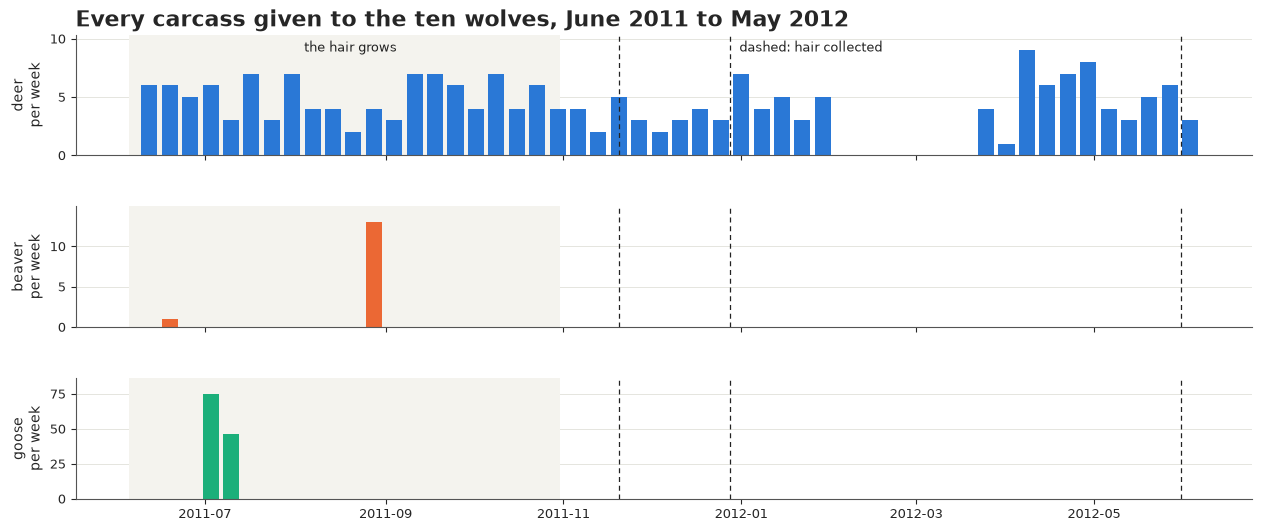

In [19]:
weekly = (feeding.drop_duplicates("item").dropna(subset=["date"]).set_index("date").groupby("species")
          .resample("W")["item"].count().unstack(0).reindex(columns=PREY).fillna(0))
fig, axes = plt.subplots(3, 1, figsize=(12.5, 5.2), sharex=True, gridspec_kw={"hspace": 0.25})
for ax, s in zip(axes, PREY):
    ax.axvspan(weekly.index.min() - pd.Timedelta(days=7), GROWTH_END, color="#f4f3ee", lw=0)
    ax.bar(weekly.index, weekly[s], width=5.5, color=PREY_COLOUR[s])
    for d in sorted(trial["date"].unique()):
        ax.axvline(pd.Timestamp(d), color=INK, lw=0.9, ls=(0, (4, 3)))
    ax.set_ylabel(f"{s}\nper week")
    ax.set_ylim(0, max(4, weekly[s].max() * 1.15))
    tidy(ax)
axes[0].text(pd.Timestamp("2011-08-20"), axes[0].get_ylim()[1] * 0.86, "the hair grows", fontsize=9, color=INK,
             ha="center")
axes[0].text(pd.Timestamp("2011-12-30"), axes[0].get_ylim()[1] * 0.86, " dashed: hair collected", fontsize=9,
             color=INK, ha="left")
axes[0].set_title("Every carcass given to the ten wolves, June 2011 to May 2012", loc="left");

Up to 31 October the ten wolves were given 106 deer, 14 beavers and 121 geese, the numbers the article
reports. Every wolf has between 98 and 104 of the deer and all of the geese to its name: they ate
together, as part 2 supposed.

**What is a share of a diet?** By number of carcasses the diet is half goose. By weight it is another
diet, because a deer weighs thirty times as much as a goose. The article weighs each carcass by a value
drawn from a range for its species (41 to 223 kg for a deer, 5 to 35 for a beaver, 3 to 6 for a goose)
and arrives at 94.1% deer, 2.0% beaver and 3.9% goose; with the middle of each range we get 94.4, 1.9
and 3.7. Isotopes follow the mass that is digested, so weight is the scale to compare with. It is
approximate too: if the average carcass of each species lay anywhere in its range, the deer share would
be between 86% and 97%. We take 94% as the truth.

The timeline holds a fact the blind analysis could not use: the geese all came within two weeks at the
end of June and the start of July, and all but one of the beavers in one week of August.

**A rival: the textbook model.** So that the test has two candidates, we add the analysis these data
would usually get. It is the configuration the article starts from: one rump sample per wolf from
November and December, the spread among prey animals inside the wolves' variance (the dashed ellipse of
part 2), the fox shift, and a flat Dirichlet prior.

In [20]:
rump = trial[(trial["site"] == "rump") & (trial["date"] < "2012-01")]          # the article's ten samples
within_var = az.extract(hair_fit["idata"], var_names=["within"]).mean("sample").to_numpy() ** 2


def textbook_posterior(G, y, shift, shift_var, prior="flat Dirichlet"):
    """Every wolf eats its own animals: var(hair) = sum p_k^2 (animal variance + shift variance) + noise."""
    P = G["P"]
    mean = P @ M_ALL + shift
    var = P**2 @ (ANIMAL_VAR + shift_var) + within_var
    loglik = (-0.5 * (y[None] - mean[:, None]) ** 2 / var[:, None] - 0.5 * np.log(var[:, None])).sum((1, 2))
    return normalise(loglik + G["prior"][prior])


w_textbook = textbook_posterior(G, rump[ISO].to_numpy(), FOX, np.diag(FOX_COV))
describe_diet(G, w_textbook, "textbook model")
describe_diet(G, w_blind, "our chain, blind")
print("fed, by weight:", shares(TRUTH))
for label, w in (("textbook model", w_textbook), ("our chain, flat Dirichlet", w_dirichlet), ("our chain", w_blind)):
    print(f"{label}: P(deer share >= {TRUTH[0]:.2f}) = {w[G['P'][:, 0] >= TRUTH[0] - 1e-9].sum():.3f}; "
          f"P(deer >= {deer_band[0]:.2f}) = {w[G['P'][:, 0] >= deer_band[0]].sum():.3f}")
needed = H - TRUTH @ M_EAT
print(f"shift that would put the truth at the centre: d13C {needed[0]:.2f}, d15N {needed[1]:.2f}; "
      f"fox: {FOX[0]}, {FOX[1]}; the gap in fox standard deviations: "
      f"{((FOX - needed) / np.sqrt(np.diag(FOX_COV))).round(1)}")

textbook model                    deer 0.54 (0.41 to 0.69) | beaver 0.20 (0.06 to 0.37) | goose 0.24 (0.07 to 0.42) | small prey 0.46 (0.31 to 0.58) | corr(beaver, goose) -0.67
our chain, blind                  deer 0.70 (0.49 to 0.95) | beaver 0.15 (0.01 to 0.39) | goose 0.10 (0.01 to 0.33) | small prey 0.30 (0.05 to 0.51) | corr(beaver, goose) -0.25
fed, by weight: {'deer': 0.944, 'beaver': 0.019, 'goose': 0.037}
textbook model: P(deer share >= 0.94) = 0.000; P(deer >= 0.86) = 0.000
our chain, flat Dirichlet: P(deer share >= 0.94) = 0.005; P(deer >= 0.86) = 0.038
our chain: P(deer share >= 0.94) = 0.056; P(deer >= 0.86) = 0.151
shift that would put the truth at the centre: d13C 1.99, d15N 2.82; fox: 2.6, 3.4; the gap in fox standard deviations: [2.2 2.9]


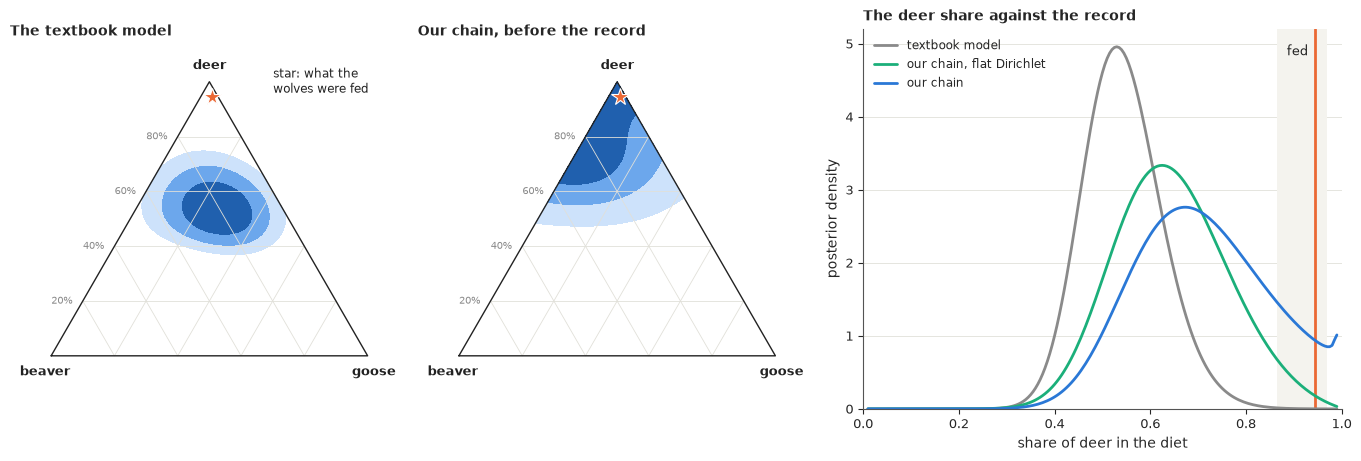

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.2]})
for ax, w, title in ((axes[0], w_textbook, "The textbook model"), (axes[1], w_blind, "Our chain, before the record")):
    ternary(ax, title)
    ternary_density(ax, G, w)
    ternary_point(ax, TRUTH)
axes[0].text(0.66, 0.86, "star: what the\nwolves were fed", fontsize=8.5, color=INK, transform=axes[0].transAxes)
ax = axes[2]
ax.axvspan(*deer_band, color="#f4f3ee", lw=0)
ax.axvline(TRUTH[0], color=ORANGE, lw=2)
for w, colour, label in ((w_textbook, MUTED, "textbook model"), (w_dirichlet, AQUA, "our chain, flat Dirichlet"),
                         (w_blind, BLUE, "our chain")):
    x, dens = marginal(G, w, 0)
    smooth = np.convolve(dens, np.ones(5) / 5, mode="same")
    ax.plot(x[2:-2], smooth[2:-2], color=colour, lw=2, label=label)
ax.text(TRUTH[0] - 0.015, ax.get_ylim()[1] * 0.93, "fed", color=INK, fontsize=9, ha="right")
ax.set_xlim(0, 1)
ax.set_ylim(0, None)
ax.set_xlabel("share of deer in the diet")
ax.set_ylabel("posterior density")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("The deer share against the record", loc="left", fontsize=10)
tidy(ax);

**The textbook model is confidently wrong.** It reports 54% deer, with a 90% interval from 41 to 69, and
about a fifth of the diet each for beaver and goose. The article reports 54% for the same configuration.
The wolves were fed 94% deer, and the model gives no probability worth printing to a share that high, or
even to the bottom of the band, 86%. Three things push it down: the dashed ellipse, under which a
deer-heavy diet predicts wolves far more varied than these and so counts against itself; the flat
Dirichlet; and the fox shift.

**Our chain is wide enough, barely.** Its 70% (50 to 95) holds the truth at its upper edge: the
posterior probability of a deer share of 94% or more is about 6%, and of 86% or more about 15%. The
interval did its job, and no more. The centre of the answer is 24 points away from what the wolves ate,
in the direction of prey they hardly touched. With a flat Dirichlet prior the same chain would have
failed outright (64%, 46 to 84).

**Where the miss comes from.** With the diet known, we can ask what shift between food and hair these
wolves show: 2.0‰ in carbon and 2.8‰ in nitrogen. The fox values are 2.6 and 3.4, higher by 0.6 in both,
which is more than two of the standard deviations quoted with them in carbon and nearly three in
nitrogen. Too large a nitrogen shift puts the reconstructed food too low in the triangle, towards
beaver; too large a carbon shift puts it too far left, towards both small prey. The standard deviations
of 0.28 and 0.20 say how well the shift is known for the foxes of one study. We used them as if they
said how well it is known for wolves. This is the second orange arrow, back to part 3.

> **The choice.** Against the record the blind chain stands, at the edge: the truth is at about the 94th
> percentile of its posterior for deer. *Rejected:* the textbook model (54% deer, 41 to 69, for a diet
> of 94%). *Considered:* calling the result a success because the interval holds the truth. On the one
> occasion we can check, it does so at its very edge, and that is a warning. *What would change our
> mind:* a second trial on another diet, which would tell us whether the chain was unlucky here or is
> biased.

## 6 · The calibration this trial was run for

The feeding trial exists to measure the shift on wolves. With the diet known, the mixing equation has
one unknown left, $\Delta = h - \sum_k p_k\,\mu_k$. A calibration fitted to these ten wolves and then
used on the same ten would be circular, so we split the pack: five wolves calibrate, and the diet of the
other five is estimated as if unknown. The split is as favourable as a test can be, since both halves
ate the same carcasses.

There are two ways to carry the calibration to the test wolves. The first is how results travel between
papers: summarise the shift as a mean and a standard deviation and plug it into the mixing model of part
4. The second is to fit calibration and diet in one model, in which the calibration wolves have their
diet fixed at the record, the test wolves have a free diet, and both halves share the prey signatures
and a shift with a prior so wide (0 ± 5‰) that nothing is borrowed from foxes.

In [22]:
shift_trial = H - TRUTH @ M_EAT                                # closed form: hair minus the food at the known diet
a_true = np.kron(TRUTH, np.eye(2))                             # 2 x 6: the known diet applied to the six prey values
shift_trial_cov = a_true @ S_EAT @ a_true.T + VH
WOLF, WOLF_COV = np.array([1.97, 3.04]), np.diag([0.70**2, 0.31**2])     # the article's estimate
print("shift between food and wolf hair, permil (mean, sd):")
print(f"  from this notebook's prey model: d13C {shift_trial[0]:.2f} ({np.sqrt(shift_trial_cov[0, 0]):.2f}), "
      f"d15N {shift_trial[1]:.2f} ({np.sqrt(shift_trial_cov[1, 1]):.2f})")
print("  Derbridge et al. (2015):         d13C 1.97 (0.70), d15N 3.04 (0.31)")
print("  red fox, as used in parts 3-5:   d13C 2.60 (0.28), d15N 3.40 (0.20)")
print("  share of the calibration's variance that comes from the deer signature:",
      (np.diag(a_true @ S_EAT @ a_true.T) / np.diag(shift_trial_cov)).round(2))

half_a = trial[trial["wolf"] <= 493]                           # five wolves to calibrate on
half_b = trial[trial["wolf"] > 493]                            # five wolves whose diet we pretend not to know
hair_a, hair_b = fit_hair(half_a), fit_hair(half_b)
note("hair, calibration half", hair_a["idata"])
note("hair, test half", hair_b["idata"])
print("\nwolves", half_a["wolf"].unique().tolist(), "calibrate;", half_b["wolf"].unique().tolist(), "are tested")
print("pack means:", hair_a["mean"].round(2), "and", hair_b["mean"].round(2))

with pm.Model(coords={"species": PREY, "iso": ISO}) as joint_model:
    src = pm.MvNormal("src", M_EAT.ravel(), cov=S_EAT, shape=6).reshape((3, 2))
    tdf = pm.Normal("shift", 0.0, 5.0, dims="iso")                               # nothing borrowed from foxes
    pm.MvNormal("hair_known", pt.dot(TRUTH, src) + tdf, cov=hair_a["cov"], observed=hair_a["mean"])
    deer_share = pm.Uniform("deer_share", 0.0, 1.0)
    split = pm.Uniform("split", 0.0, 1.0)
    p = pm.Deterministic("p", pt.stack([deer_share, (1 - deer_share) * split, (1 - deer_share) * (1 - split)]),
                         dims="species")
    pm.MvNormal("hair_unknown", pt.dot(p, src) + tdf, cov=hair_b["cov"], observed=hair_b["mean"])
    idata_joint = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.95)
note("calibration and mixing, jointly", idata_joint)
print(pd.DataFrame(DIAG[-3:]).to_string(index=False))


def joint_posterior(G, h_known, V_known, h_unknown, V_unknown, p_known, prior_sd=5.0):
    """Exact version of the joint model: both halves share the prey values and the shift."""
    P = G["P"]
    A = np.zeros((len(P), 2, 6))
    for k in range(3):
        A[:, 0, 2 * k] = A[:, 1, 2 * k + 1] = P[:, k]
    A0 = np.kron(p_known, np.eye(2))
    D0 = prior_sd**2 * np.eye(2)
    cov = np.zeros((len(P), 4, 4))
    cov[:, :2, :2] = A0 @ S_EAT @ A0.T + D0 + V_known
    cov[:, :2, 2:] = np.swapaxes(A @ S_EAT @ A0.T, 1, 2) + D0
    cov[:, 2:, :2] = A @ S_EAT @ A0.T + D0
    cov[:, 2:, 2:] = A @ S_EAT @ A.transpose(0, 2, 1) + D0 + V_unknown
    r = np.concatenate([np.broadcast_to(h_known - p_known @ M_EAT, (len(P), 2)), h_unknown - P @ M_EAT], 1)
    loglik = -0.5 * np.einsum("na,nab,nb->n", r, np.linalg.inv(cov), r) - 0.5 * np.log(np.linalg.det(cov))
    return normalise(loglik + G["prior"]["flat on the question"])


w_joint = joint_posterior(G, hair_a["mean"], hair_a["cov"], hair_b["mean"], hair_b["cov"], TRUTH)
shift_a = hair_a["mean"] - TRUTH @ M_EAT
shift_a_cov = a_true @ S_EAT @ a_true.T + hair_a["cov"]
w_summary = diet_posterior(G, hair_b["mean"], hair_b["cov"], M_EAT, S_EAT, shift_a, shift_a_cov)
w_fox_b = diet_posterior(G, hair_b["mean"], hair_b["cov"], M_EAT, S_EAT, FOX, FOX_COV)
p_joint = az.extract(idata_joint, var_names=["p"]).transpose("sample", "species").to_numpy()
print("\nthe five test wolves, fed", shares(TRUTH, 2))
describe_diet(G, w_fox_b, "fox shift")
describe_diet(G, w_summary, "wolf shift, passed as a summary")
describe_diet(G, w_joint, "wolf shift, fitted jointly")
print("joint model, NUTS, deer share 5%, 50%, 95%:", np.quantile(p_joint[:, 0], [0.05, 0.5, 0.95]).round(2))
print("correlation between the shift and the deer signature in the joint posterior (d13C, d15N):",
      [round(float(np.corrcoef(idata_joint.posterior["shift"].sel(iso=iso).to_numpy().ravel(),
                               idata_joint.posterior["src"].to_numpy().reshape(-1, 6)[:, t])[0, 1]), 2)
       for t, iso in enumerate(ISO)])

shift between food and wolf hair, permil (mean, sd):
  from this notebook's prey model: d13C 1.99 (0.62), d15N 2.82 (0.49)
  Derbridge et al. (2015):         d13C 1.97 (0.70), d15N 3.04 (0.31)
  red fox, as used in parts 3-5:   d13C 2.60 (0.28), d15N 3.40 (0.20)
  share of the calibration's variance that comes from the deer signature: [0.95 0.99]



wolves [480, 486, 487, 488, 493] calibrate; [494, 495, 496, 497, 498] are tested
pack means: [-20.3    7.09] and [-20.17   7.16]


                          model  divergences  max r_hat  min ESS
         hair, calibration half            0      1.004      790
                hair, test half            0      1.004     1120
calibration and mixing, jointly            0      1.003      932

the five test wolves, fed {'deer': 0.94, 'beaver': 0.02, 'goose': 0.04}
fox shift                         deer 0.71 (0.51 to 0.95) | beaver 0.14 (0.01 to 0.38) | goose 0.10 (0.01 to 0.32) | small prey 0.29 (0.05 to 0.49) | corr(beaver, goose) -0.22
wolf shift, passed as a summary   deer 0.84 (0.56 to 0.99) | beaver 0.06 (0.00 to 0.28) | goose 0.06 (0.00 to 0.30) | small prey 0.16 (0.01 to 0.44) | corr(beaver, goose) +0.04
wolf shift, fitted jointly        deer 0.95 (0.83 to 1.00) | beaver 0.01 (0.00 to 0.08) | goose 0.02 (0.00 to 0.12) | small prey 0.05 (0.00 to 0.17) | corr(beaver, goose) +0.15
joint model, NUTS, deer share 5%, 50%, 95%: [0.83 0.94 0.99]
correlation between the shift and the deer signature in the joint posterior

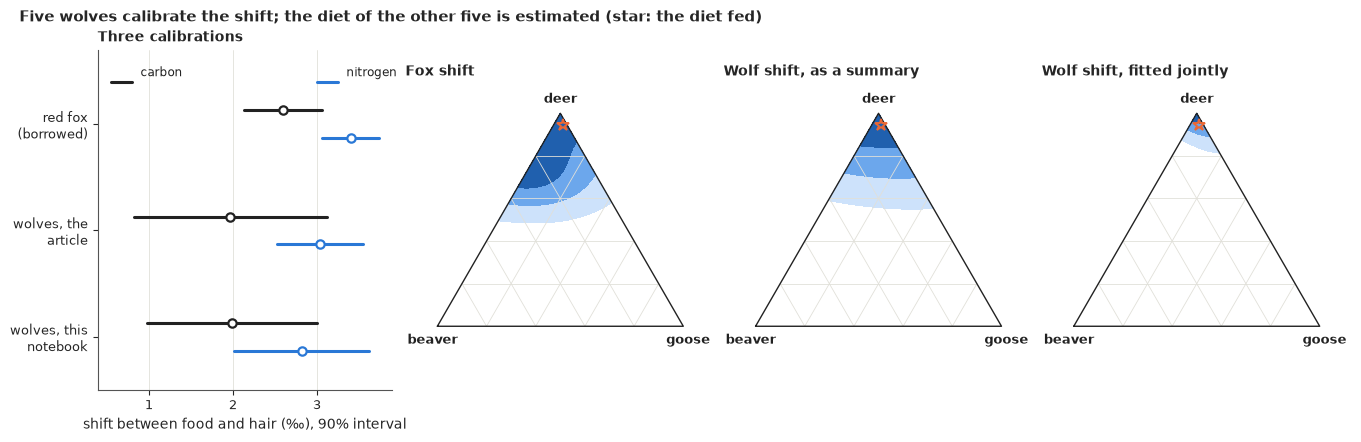

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.1), gridspec_kw={"width_ratios": [0.95, 1, 1, 1]})
ax = axes[0]
rows = [("red fox\n(borrowed)", FOX, np.sqrt(np.diag(FOX_COV))),
        ("wolves, the\narticle", WOLF, np.sqrt(np.diag(WOLF_COV))),
        ("wolves, this\nnotebook", shift_trial, np.sqrt(np.diag(shift_trial_cov)))]
for r_, (label, mean, sd) in enumerate(rows):
    for t, (colour, off) in enumerate(((INK, -0.13), (BLUE, 0.13))):
        ax.plot([mean[t] - 1.645 * sd[t], mean[t] + 1.645 * sd[t]], [r_ + off, r_ + off], color=colour, lw=2.2,
                solid_capstyle="round")
        ax.plot(mean[t], r_ + off, "o", ms=6, color="white", mec=colour, mew=1.6)
ax.set_yticks(range(3), [r[0] for r in rows])
ax.set_ylim(2.5, -0.7)
ax.text(0.9, -0.45, "carbon", color=INK, fontsize=8.5)
ax.text(3.35, -0.45, "nitrogen", color=INK, fontsize=8.5)
ax.plot([0.55, 0.8], [-0.4, -0.4], color=INK, lw=2.2)
ax.plot([3.0, 3.25], [-0.4, -0.4], color=BLUE, lw=2.2)
ax.set_xlabel("shift between food and hair (‰), 90% interval")
ax.set_title("Three calibrations", loc="left", fontsize=10)
tidy(ax, grid="x")
for ax, w, title in ((axes[1], w_fox_b, "Fox shift"), (axes[2], w_summary, "Wolf shift, as a summary"),
                     (axes[3], w_joint, "Wolf shift, fitted jointly")):
    ternary(ax, title, labels=False)
    ternary_density(ax, G, w)
    ternary_point(ax, TRUTH, ms=9, color="none", mec=ORANGE, mew=1.4)
fig.suptitle("Five wolves calibrate the shift; the diet of the other five is estimated (star: the diet fed)",
             x=0.01, y=1.04, ha="left", fontsize=11);

**The calibration.** From our prey model the shift is 2.0 ± 0.6‰ for carbon and 2.8 ± 0.5‰ for nitrogen;
the article reports 1.97 ± 0.70 and 3.04 ± 0.31, from a different treatment of the same animals. Both
sit below the fox values. The uncertainty is large for a trial with 38 hair samples, and the printed
line says why: 95% and 99% of its variance comes from not knowing the deer signature.

**Passed as a summary, the calibration helps a little.** The test wolves come out at 84% deer (56 to
99): better centred than with the fox shift (71%, 51 to 95), and no narrower. The article found the same
on its own terms: a wolf-specific shift alone did not recover the diet, and the authors concluded that
an informative prior mattered more.

**Fitted jointly, it recovers the diet.** 95% deer (83 to 100), around a truth of 94. The data and the
calibration are the same; the difference is in what was passed along. In the joint posterior the shift
and the deer signature are correlated at -0.95 (carbon) and -0.99 (nitrogen): if the deer mean is higher
than we think, the shift is lower by the same amount, and their sum, which is all that the hair of a
deer-eating wolf depends on, is known far better than either term. A mean and a standard deviation for
the shift throw that correlation away.

This is the best case and should be read as one: the test wolves ate the calibration wolves' prey, so
every error about that prey cancels. A field study borrows the shift from a trial and meets different
deer, and there a summary is all that can travel; the 84% (56 to 99) is the honest preview. The
principle carries over: when one model's output is another's input and the two share anything, pass the
joint posterior.

> **The choice.** Where calibration animals and study animals share prey, one joint model. For the next
> study, the wolf shift from this trial as a summary: 2.0 ± 0.6‰ and 2.8 ± 0.5‰. *Rejected:* the fox
> shift with the uncertainty reported for foxes. *Considered:* the article's values, which agree with
> ours within their uncertainty; part 8 uses them, as the published numbers a reader would reach for.
> *What would change our mind:* a second pair of species. One fox study and one wolf trial give a single
> measurement of how far a borrowed shift can be off, 0.6‰, too few to make a rule.

## 7 · Another tracer, or something else?

A biologist planning the next season can spend on more hair, more prey samples, a better calibration, or
a third tracer measured in everything. When a mixing model returns wide intervals, the usual advice is
the third tracer. We look first at what the second one bought here, on the real data, and then simulate
the rest.

In [24]:
w_c = diet_posterior(G, H, VH, M_EAT, S_EAT, shift_trial, shift_trial_cov, tracers=[0])
w_n = diet_posterior(G, H, VH, M_EAT, S_EAT, shift_trial, shift_trial_cov, tracers=[1])
w_cn = diet_posterior(G, H, VH, M_EAT, S_EAT, shift_trial, shift_trial_cov)
print("the real hair, with the wolf shift of part 6 (which was calibrated on this very diet):")
describe_diet(G, w_c, "carbon only")
describe_diet(G, w_n, "nitrogen only")
describe_diet(G, w_cn, "carbon and nitrogen")
print("distance between prey means in units of their joint uncertainty (sources and shift):")
for a_, b_ in ((0, 1), (0, 2), (1, 2)):
    sd = np.sqrt(np.diag(S_EAT)[2 * a_:2 * a_ + 2] + np.diag(S_EAT)[2 * b_:2 * b_ + 2] + np.diag(shift_trial_cov))
    print(f"  {PREY[a_]} to {PREY[b_]}: d13C {abs(M_EAT[a_, 0] - M_EAT[b_, 0]) / sd[0]:.1f}, "
          f"d15N {abs(M_EAT[a_, 1] - M_EAT[b_, 1]) / sd[1]:.1f}")

the real hair, with the wolf shift of part 6 (which was calibrated on this very diet):
carbon only                       deer 0.82 (0.52 to 0.99) | beaver 0.07 (0.00 to 0.34) | goose 0.07 (0.00 to 0.29) | small prey 0.18 (0.01 to 0.48) | corr(beaver, goose) +0.01
nitrogen only                     deer 0.65 (0.11 to 0.98) | beaver 0.10 (0.00 to 0.41) | goose 0.17 (0.01 to 0.73) | small prey 0.35 (0.02 to 0.89) | corr(beaver, goose) -0.00
carbon and nitrogen               deer 0.83 (0.56 to 0.99) | beaver 0.07 (0.00 to 0.28) | goose 0.07 (0.00 to 0.30) | small prey 0.17 (0.01 to 0.44) | corr(beaver, goose) +0.02
distance between prey means in units of their joint uncertainty (sources and shift):
  deer to beaver: d13C 3.1, d15N 2.5
  deer to goose: d13C 3.6, d15N 0.5
  beaver to goose: d13C 1.0, d15N 2.4


With the wolf shift of part 6, carbon alone puts the deer share at 82% (52 to 99), and adding nitrogen
gives 83% (56 to 99). The second tracer bought almost nothing for the main question, and the last lines
say why. In units of the combined uncertainty of prey and shift, deer and goose are 3.6 apart in carbon
and half a unit apart in nitrogen: nitrogen cannot tell a deer from a goose. It can tell beaver from the
other two, which is why it trims the beaver share a little and leaves deer alone. A tracer is worth what
it separates, measured against what is not known about the prey and the shift. (These fits use a shift
calibrated on this very diet, so their centres are right by construction; the widths are what we read.)

For everything else we simulate, and it should be plain what is real. The geometry is real: the prey
signatures and their uncertainties from part 4, the wolf shift from part 6, the precision of a pack mean
from part 1. The packs are simulated: for a chosen true diet we draw true prey signatures and a true
shift from those distributions, draw the hair, and compute the posterior on a coarser grid. An
investment changes what the analyst knows beforehand. Four times the hair samples halve the standard
deviation of the pack mean. Four times the prey animals halve those of the prey signatures, which is
optimistic, since unsampled months limit the deer signature more than the number of animals does. A
better trial halves those of the shift.

The third tracer is invented: nobody measured one. We give it favourable properties (prey means known to
0.4‰, a shift known to 0.3‰) and two possible geometries. In one it splits the small prey: beaver and
goose are 4‰ apart, with deer between them. In the other it sets deer 4‰ apart from both, as carbon
does.

In [25]:
G_SIM = make_grid(80)
THIRD = {"splits the small prey": np.array([0.0, -2.0, 2.0]), "sets deer apart again": np.array([0.0, 4.0, 4.0])}
THIRD_SD = {"source": 0.4, "shift": 0.3, "hair": 0.1}             # assumed for the tracer nobody measured


def one_future(p_true, gen, hair_x=1.0, source_x=1.0, shift_x=1.0, third=None):
    """Simulate the pack's hair for a diet, after an investment, and return the posterior on the grid.
    hair_x, source_x, shift_x multiply the standard deviations of today's knowledge (0.5 = twice as good)."""
    def refine(mean, cov, x):
        """What better knowledge will say: its new centre is itself uncertain today."""
        new_cov = cov * x**2
        centre = gen.multivariate_normal(mean, cov - new_cov) if x < 1 else mean
        return centre, new_cov, gen.multivariate_normal(centre, new_cov)

    M, S, src_true = refine(M_EAT.ravel(), S_EAT, source_x)
    d, D, shift_true = refine(shift_trial, shift_trial_cov, shift_x)
    M, src_true, Vh = M.reshape(3, 2), src_true.reshape(3, 2), VH * hair_x**2
    h = gen.multivariate_normal(p_true @ src_true + shift_true, Vh)
    if third is not None:                                         # a third, simulated, tracer
        m3_true = THIRD[third] + gen.normal(0, THIRD_SD["source"], 3)
        h3 = p_true @ m3_true + gen.normal(0, THIRD_SD["shift"]) + gen.normal(0, THIRD_SD["hair"])
        M = np.column_stack([M, THIRD[third]])
        S3 = np.zeros((9, 9))
        keep = [0, 1, 3, 4, 6, 7]
        S3[np.ix_(keep, keep)] = S
        S3[[2, 5, 8], [2, 5, 8]] = THIRD_SD["source"] ** 2
        S = S3
        d, h = np.append(d, 0.0), np.append(h, h3)
        D = np.pad(D, (0, 1))
        D[2, 2] = THIRD_SD["shift"] ** 2
        Vh = np.pad(Vh, (0, 1))
        Vh[2, 2] = THIRD_SD["hair"] ** 2
    return diet_posterior(G_SIM, h, Vh, M, S, d, D)


OPTIONS = {
    "as in this trial": {},
    "four times the hair samples": {"hair_x": 0.5},
    "four times the prey animals": {"source_x": 0.5},
    "a shift known twice as well": {"shift_x": 0.5},
    "third tracer: splits the small prey": {"third": "splits the small prey"},
    "third tracer: sets deer apart again": {"third": "sets deer apart again"},
}
DIETS = {"a deer specialist (90 / 5 / 5)": np.array([0.90, 0.05, 0.05]),
         "a mixed diet (50 / 25 / 25)": np.array([0.50, 0.25, 0.25])}
N_SIM = 300
t0 = time.time()
sim_rows, example = [], {}
for diet_name, p_true in DIETS.items():
    for option, kw in OPTIONS.items():
        gen = np.random.default_rng(RANDOM_SEED + 7)             # the same futures for every option
        widths = np.empty((N_SIM, 2))
        covered = 0
        for r_ in range(N_SIM):
            w = one_future(p_true, gen, **kw)
            lo, _, hi = quantiles(w, G_SIM["P"][:, 0])
            lo_b, _, hi_b = quantiles(w, G_SIM["P"][:, 1])
            widths[r_] = hi - lo, hi_b - lo_b
            covered += lo <= p_true[0] <= hi
            if r_ == 0:
                example[(diet_name, option)] = w
        sim_rows.append({"diet": diet_name, "option": option, "deer: width of 90% interval": np.median(widths[:, 0]),
                         "deer lo": np.quantile(widths[:, 0], 0.1), "deer hi": np.quantile(widths[:, 0], 0.9),
                         "beaver: width of 90% interval": np.median(widths[:, 1]),
                         "beaver lo": np.quantile(widths[:, 1], 0.1), "beaver hi": np.quantile(widths[:, 1], 0.9),
                         "truth inside": covered / N_SIM})
sims = pd.DataFrame(sim_rows)
print(f"{len(sims) * N_SIM:,} simulated packs in {time.time() - t0:.0f} s")
print(sims[["diet", "option", "deer: width of 90% interval", "beaver: width of 90% interval", "truth inside"]]
      .round(2).to_string(index=False))

3,600 simulated packs in 8 s
                          diet                              option  deer: width of 90% interval  beaver: width of 90% interval  truth inside
a deer specialist (90 / 5 / 5)                    as in this trial                         0.46                           0.30          0.93
a deer specialist (90 / 5 / 5)         four times the hair samples                         0.45                           0.29          0.92
a deer specialist (90 / 5 / 5)         four times the prey animals                         0.41                           0.28          0.96
a deer specialist (90 / 5 / 5)         a shift known twice as well                         0.35                           0.22          0.96
a deer specialist (90 / 5 / 5) third tracer: splits the small prey                         0.46                           0.26          0.92
a deer specialist (90 / 5 / 5) third tracer: sets deer apart again                         0.26                           0.1

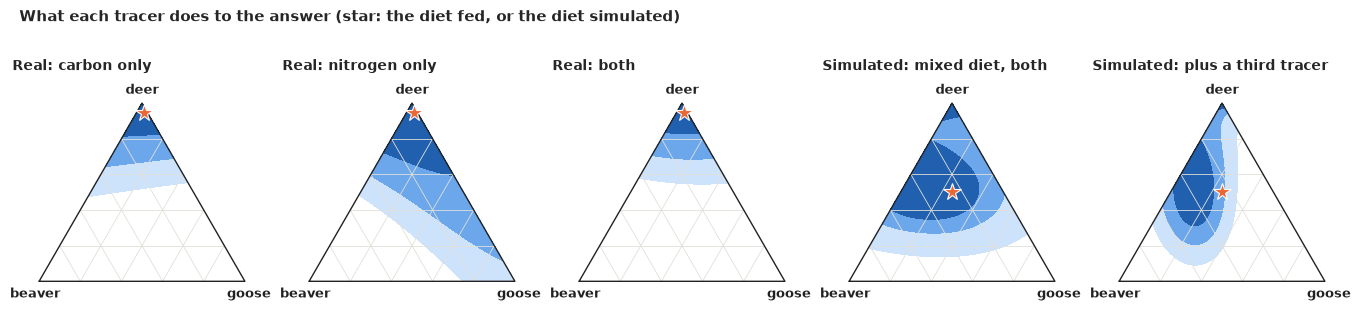

In [26]:
fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.5))
panels = [(w_c, "Real: carbon only"), (w_n, "Real: nitrogen only"), (w_cn, "Real: both"),
          (example[("a mixed diet (50 / 25 / 25)", "as in this trial")], "Simulated: mixed diet, both"),
          (example[("a mixed diet (50 / 25 / 25)", "third tracer: splits the small prey")],
           "Simulated: plus a third tracer")]
for ax, (w, title) in zip(axes, panels):
    g_ = G if len(w) == len(G["P"]) else G_SIM
    ternary(ax, title, labels=False)
    ternary_density(ax, g_, w)
    ternary_point(ax, TRUTH if g_ is G else DIETS["a mixed diet (50 / 25 / 25)"])
fig.suptitle("What each tracer does to the answer (star: the diet fed, or the diet simulated)", x=0.01, ha="left",
             fontsize=11);

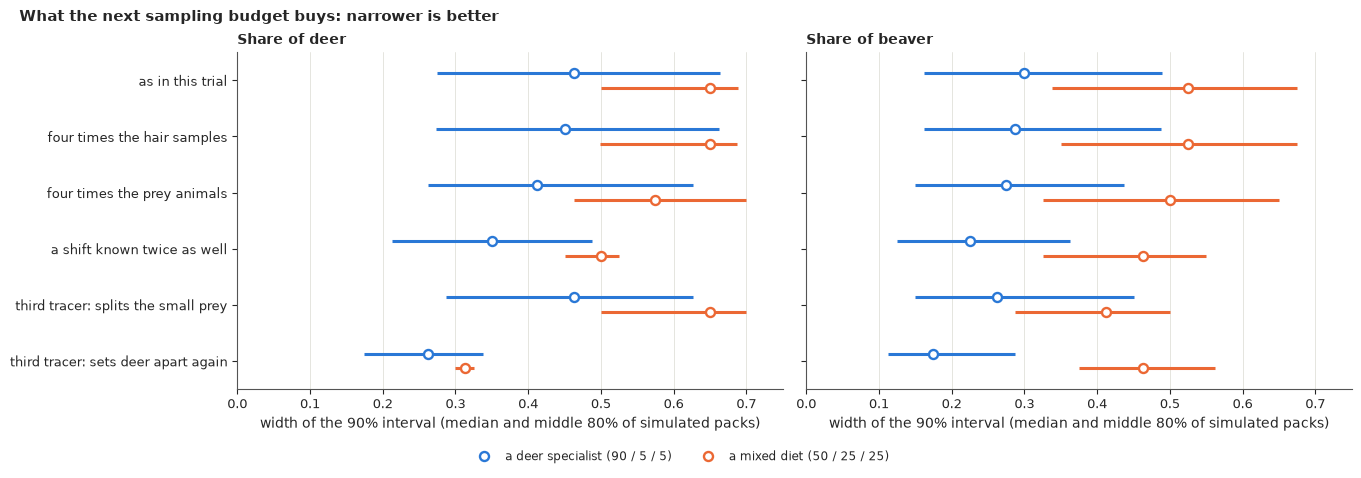

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), sharey=True)
names = list(OPTIONS)
for ax, col, title in ((axes[0], "deer", "Share of deer"), (axes[1], "beaver", "Share of beaver")):
    for d_, (diet_name, colour) in enumerate(zip(DIETS, (BLUE, ORANGE))):
        sub = sims[sims["diet"] == diet_name].set_index("option").loc[names]
        y = np.arange(len(names)) + (d_ - 0.5) * 0.26
        ax.hlines(y, sub[f"{col} lo"], sub[f"{col} hi"], color=colour, lw=2.2)
        ax.plot(sub[f"{col}: width of 90% interval"], y, "o", ms=6.5, color="white", mec=colour, mew=1.7,
                label=diet_name)
    ax.set_yticks(range(len(names)), names)
    ax.set_ylim(len(names) - 0.5, -0.5)
    ax.set_xlim(0, 0.75)
    ax.set_xlabel("width of the 90% interval (median and middle 80% of simulated packs)")
    ax.set_title(title, loc="left", fontsize=10)
    tidy(ax, grid="x")
handles, labels_ = axes[1].get_legend_handles_labels()
fig.legend(handles, labels_, frameon=False, fontsize=8.5, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.09))
fig.suptitle("What the next sampling budget buys: narrower is better", x=0.01, ha="left", fontsize=11);

**More hair buys nothing.** Four times the samples leave every interval where it was: the uncertainty
that limits the answer is shared by every hair. **More prey animals buy little**, about 5 points off the
width of the deer interval for a deer specialist and 8 for a mixed diet, under the optimistic assumption
above.

**A better calibration is worth more.** Halving the uncertainty of the shift narrows the deer interval
from 0.46 to 0.35 for the specialist and from 0.65 to 0.50 for the mixed diet.

**A third tracer is worth a great deal or nothing, depending on what it separates.** One that sets deer
apart again nearly halves the interval for the deer share (0.26 and 0.31). One that splits the small
prey leaves the deer share exactly as uncertain as before and narrows only the beaver share, from 0.52
to 0.41 in the mixed diet. The two right-hand triangles show one simulated pack before and after that
tracer: the region is squeezed sideways, between beaver and goose, and keeps its height.

This is where the proposal that started this notebook meets the data. The proposal was that when sources
line up in isotope space the posterior is a ridge, and the analyst must choose between an informative
prior, merging sources, or a third tracer. Here the sources do not line up, and the ridge between beaver
and goose is mild. What limits the answer is uncertainty shared by all hairs, in the shift and in the
deer signature, and it acts along the axis from deer to small prey: across the ridge, not along it.
Merging is the right way to report (part 4), an informative prior moves the answer more than any
measurement (part 8), and a third tracer aimed at the ridge would answer a question nobody asked.

> **The choice.** For a pack that eats mostly one large prey: no more hair, a calibration fitted jointly
> with known-diet animals where that is possible, and a third tracer only if it separates the main prey
> from the rest. *Rejected:* a third tracer chosen because it resolves the trade-off between the two
> minor prey. *Considered:* costs, which the biologist knows and the figure does not. *What would change
> our mind:* a real third tracer in these samples. Everything about it here is assumed, including a
> shift known to 0.3‰, which parts 5 and 6 give reason to doubt.

## 8 · Which of our choices mattered?

Five choices in the blind chain had rivals that a competent analyst might have taken: the measurement
error of the hair (two options), what a prey signature is (four), the shift (three), the prior (three)
and the tracers used (two). That makes 144 analyses of the same 38 hair samples. Two of the options are
not blind: the wolf shift from the article was calibrated on these wolves with their diet known, and the
informative prior, Dirichlet(13, 1, 1), is the one the article arrives at as the least informative that
recovers the recorded diet. The exact grid runs all 144 in about a second. The figure is a specification
curve (Simonsohn, Simmons and Nelson 2020): every analysis, in order of its answer, with the choices
that define it underneath.

In [28]:
FORKS = {  # choice: {option: inputs}; the first option of each is the one the blind chain used
    "hair": {"replicate model": (H, VH), "laboratory precision": (hair_lab["mean"], hair_lab["cov"])},
    "prey": {"batches partly pooled": (M_EAT, S_EAT), "all deer alike": (M_ALL, S_ALL),
             "summer deer only": (M_WIN, S_WIN), "means taken as known": (M_ALL, np.zeros((6, 6)))},
    "shift": {"fox, with its sd": (FOX, FOX_COV), "fox, taken as known": (FOX, NO_COV),
              "wolf, from the article": (WOLF, WOLF_COV)},
    "prior": {"flat on the question": None, "flat Dirichlet": None, "informative": None},
    "tracers": {"carbon and nitrogen": None, "carbon only": [0]},
}
t0 = time.time()
worlds = []
for hair_opt, (h_, vh_) in FORKS["hair"].items():
    for prey_opt, (m_, s_) in FORKS["prey"].items():
        for shift_opt, (d_, dc_) in FORKS["shift"].items():
            for prior_opt in FORKS["prior"]:
                for tracer_opt, tr in FORKS["tracers"].items():
                    w = diet_posterior(G, h_, vh_, m_, s_, d_, dc_, prior=prior_opt, tracers=tr)
                    lo, mid, hi = quantiles(w, G["P"][:, 0])
                    worlds.append({"hair": hair_opt, "prey": prey_opt, "shift": shift_opt, "prior": prior_opt,
                                   "tracers": tracer_opt, "lo": lo, "deer": mid, "hi": hi,
                                   "P(deer >= fed)": w[G["P"][:, 0] >= TRUTH[0] - 1e-9].sum()})
worlds = pd.DataFrame(worlds)
worlds["covers"] = (worlds["lo"] <= TRUTH[0]) & (worlds["hi"] >= TRUTH[0])
worlds["rejected"] = sum((worlds[f] != next(iter(FORKS[f]))).astype(int) for f in FORKS)
print(f"{len(worlds)} analyses in {time.time() - t0:.1f} s; the 90% interval for deer holds the fed share "
      f"({TRUTH[0]:.2f}) in {worlds['covers'].sum()} of them")
print(f"medians from {worlds['deer'].min():.2f} to {worlds['deer'].max():.2f}; intervals that hold the truth, "
      f"by prior: {worlds.groupby('prior')['covers'].sum().to_dict()}")
ours = worlds[worlds["rejected"] == 0].iloc[0]
print(f"the blind chain: deer {ours['deer']:.2f} ({ours['lo']:.2f} to {ours['hi']:.2f})")
effects = []
for f, options in FORKS.items():
    for opt in options:
        sub = worlds[worlds[f] == opt]
        alone = worlds[(worlds[f] == opt) & (worlds["rejected"] == (opt != next(iter(options))))].iloc[0]
        effects.append({"choice": f, "option": opt, "this fork alone: deer": alone["deer"],
                        "interval": f"{alone['lo']:.2f} to {alone['hi']:.2f}",
                        "median over all analyses": sub["deer"].median(),
                        "mean width": (sub["hi"] - sub["lo"]).mean(),
                        "interval holds the truth": sub["covers"].mean()})
print(pd.DataFrame(effects).round(2).to_string(index=False))

144 analyses in 1.2 s; the 90% interval for deer holds the fed share (0.94) in 53 of them
medians from 0.45 to 0.90; intervals that hold the truth, by prior: {'flat Dirichlet': 0, 'flat on the question': 22, 'informative': 31}
the blind chain: deer 0.70 (0.49 to 0.95)
 choice                 option  this fork alone: deer     interval  median over all analyses  mean width  interval holds the truth
   hair        replicate model                   0.70 0.49 to 0.95                      0.72        0.33                      0.39
   hair   laboratory precision                   0.66 0.44 to 0.93                      0.69        0.36                      0.35
   prey  batches partly pooled                   0.70 0.49 to 0.95                      0.73        0.40                      0.61
   prey         all deer alike                   0.72 0.53 to 0.94                      0.75        0.37                      0.50
   prey       summer deer only                   0.50 0.38 to 0.65          

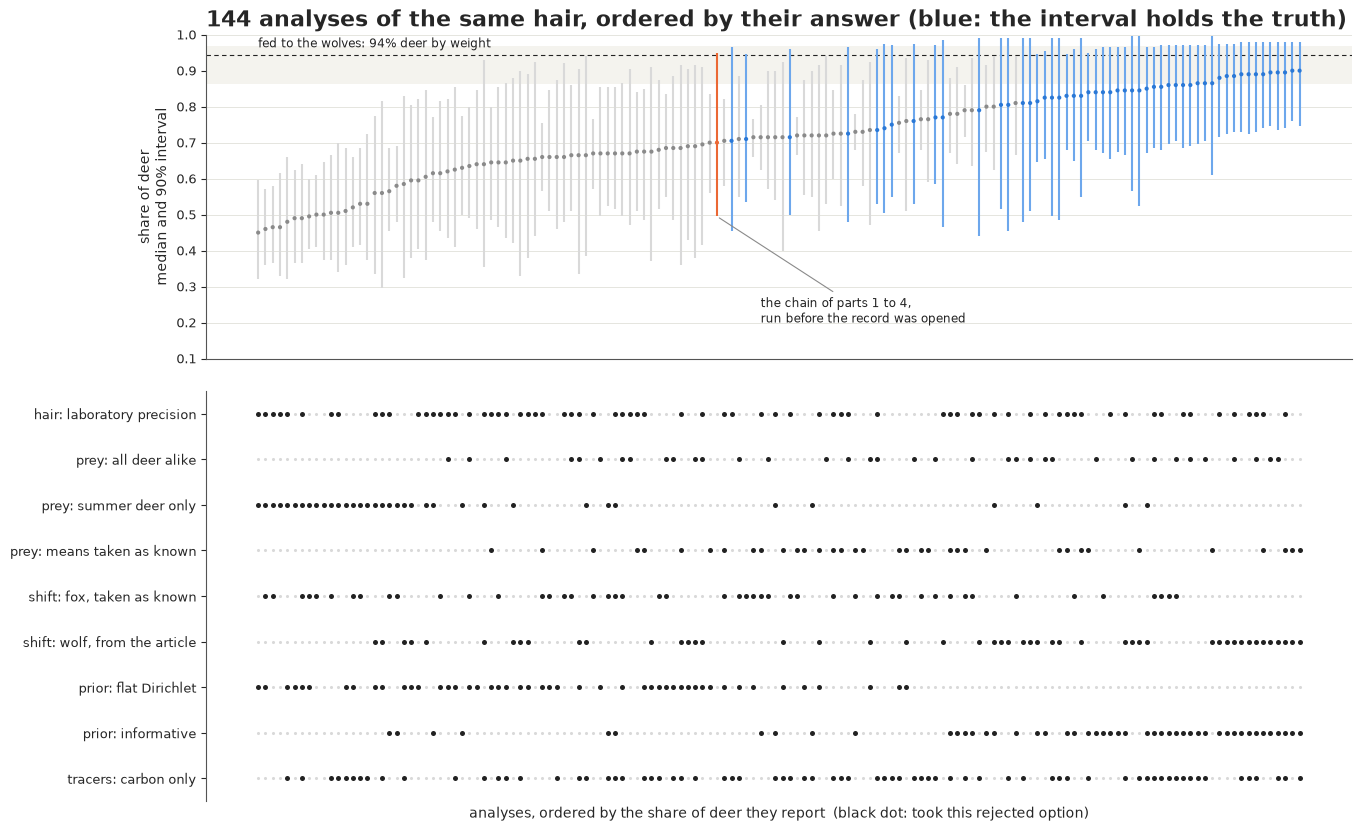

In [29]:
ws = worlds.sort_values(["deer", "hi"]).reset_index(drop=True)
fig, axes = plt.subplots(2, 1, figsize=(13.5, 8.2), sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1.9], "hspace": 0.06})
xw = np.arange(len(ws))
is_ours = (ws["rejected"] == 0).to_numpy()
ax = axes[0]
ax.axhspan(*deer_band, color="#f4f3ee", lw=0)
ax.axhline(TRUTH[0], color=INK, lw=0.8, ls=(0, (4, 3)))
colours = np.where(ws["covers"], "#6da7ec", LIGHT)
ax.vlines(xw, ws["lo"], ws["hi"], color=np.where(is_ours, ORANGE, colours), lw=1.5)
ax.scatter(xw, ws["deer"], s=9, color=np.where(is_ours, ORANGE, np.where(ws["covers"], BLUE, MUTED)), zorder=3, lw=0)
ax.text(0, TRUTH[0] + 0.012, "fed to the wolves: 94% deer by weight", fontsize=8.5, color=INK, va="bottom")
ax.annotate("the chain of parts 1 to 4,\nrun before the record was opened",
            (xw[is_ours][0], ws["lo"][is_ours].iloc[0]), (xw[is_ours][0] + 6, 0.2), fontsize=8.8, color=INK,
            arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax.set_ylim(0.1, 1.0)
ax.set_ylabel("share of deer\nmedian and 90% interval")
ax.set_title("144 analyses of the same hair, ordered by their answer (blue: the interval holds the truth)",
             loc="left")
tidy(ax)
ax = axes[1]
rows_ = [(f, opt) for f, options in FORKS.items() for opt in list(options)[1:]]
for r_, (f, opt) in enumerate(rows_):
    on = (ws[f] == opt).to_numpy()
    ax.scatter(xw[~on], np.full((~on).sum(), r_), s=5, color=LIGHT, lw=0)
    ax.scatter(xw[on], np.full(on.sum(), r_), s=13, color=INK, lw=0)
ax.set_yticks(range(len(rows_)), [f"{f}: {opt}" for f, opt in rows_])
ax.set_ylim(len(rows_) - 0.5, -0.5)
ax.set_xticks([])
ax.set_xlabel("analyses, ordered by the share of deer they report  (black dot: took this rejected option)")
ax.grid(False)
ax.spines[["top", "right", "bottom"]].set_visible(False);

Read the figure from the bottom. Each column is an analysis, and the black dots say which rejected
options it took. The top panel shows its median and 90% interval for the deer share, in blue when the
interval holds the 94% the wolves were fed. The orange column is the chain as we ran it before opening
the record.

**The answers run from 45% deer to 90%**, for the same hair and the same prey. A little over a third of
the intervals hold the truth.

**The prior decides more than any measurement.** With the flat Dirichlet, not one of 48 analyses holds
the truth. With the prior that is flat on the question, about half do. With the informative prior two
thirds do, and the answers move up by more than 10 points; it is also the one option that needed the
answer in advance. This agrees with the article's conclusion, that priors matter more than a
species-specific shift, with a qualification: part of what the informative prior repaired was damage
done by the "uninformative" one.

**Which deer is the next largest choice, and the dangerous one.** Summer deer only puts the answer near
50% and holds the truth in 1 analysis in 12. It had the best argument behind it, and five animals could
not bear the weight. Taking the prey means as known keeps the centre and halves the number of intervals
that hold the truth.

**The shift moves the centre by 10 points** (fox 70%, wolf 80%), and the wolf shift, with its larger
uncertainty, widens the interval, which is how the truth gets in. **Two choices hardly matter**: the
laboratory's precision in place of the replicate model costs 4 points, through the one odd sample, and
dropping nitrogen changes little.

The lesson is about where the effort goes. In a mixing analysis it usually goes into the consumer: more
animals, more samples, cleaner laboratory work. Here the hair was the best-known quantity in the chain
by a wide margin. The answer was decided by a prior that few think of as a choice, by a definition of
which prey counts, and by a number borrowed from foxes.

## Summary

- **The hair was the strongest link.** Replicate pairs put the noise of one sample at 0.47‰ in carbon,
  about five times the instrument's precision, and still the pack mean is known to 0.14‰. *Limit:* no
  reference materials were published, so the instrument and the hair cannot be told apart.
- **A prey signature is the mean of what was eaten, and which animals count is a model.** The spread
  among deer predicts wolves 1.2 to 2.1‰ apart in carbon; they are about 0.25 apart. All deer alike
  gives 72% deer, the five summer deer 50%, batches partly pooled 70%. *Limit:* three of the five
  months of hair growth have no sampled deer.
- **A flat Dirichlet is an opinion.** It gives a deer specialist a prior chance of 1 in 100, and none
  of the 48 analyses that use it holds the truth.
- **The blind answer was 70% deer (50 to 95); the wolves were fed 94%.** The truth sits at about the
  94th percentile; the textbook model, with 54% (41 to 69), misses it altogether. The borrowed shift
  was off by 0.6‰, two to three of the standard deviations quoted with it: a standard deviation among
  the foxes of one study is not the uncertainty about another species. *Limit:* one trial, one diet,
  and "94%" is by carcass weight (86 to 97).
- **Pass joint posteriors between models that share something.** A wolf calibration passed as a mean
  and a standard deviation gives 84% (56 to 99); fitted jointly with the diet it gives 95% (83 to
  100). *Limit:* a best case, in which test and calibration animals ate the same prey.
- **What to measure next.** In simulated packs, more hair changes nothing; a shift known twice as well
  narrows the deer interval from 0.46 to 0.35; a third tracer narrows it to 0.26 if it sets the main
  prey apart, and not at all if it only splits the minor prey. *Limit:* the third tracer is assumed.
- **For a field study.** Report the main prey against the rest, and the minor prey together; state the
  prior on that scale; rerun with the prey restricted to the season of the tissue; and treat the
  shift, not the consumer's tissue, as the term that sets the width.

## Try it yourself

1. **One wolf at a time.** Store each wolf's mean as a `pm.Deterministic` in `fit_hair`, and give each
   wolf its own deer share, drawn around a pack value on the logit scale (Semmens et al. 2009 do this
   for wild wolves). These ten ate the same meals: how much difference between wolves does the model
   report?
2. **The hair of the year before.** The ten samples of 8 July 2011 were set aside. Run them through
   `fit_hair` and the blind chain of part 4. How far is the diet they suggest from the trial's?
3. **A prior on the wrong scale.** Suppose 20 scats had been collected, and 9 held deer, 1 beaver and
   10 goose: the diet by number of carcasses. Add `"scats": 9 * np.log(safe[:, 0]) + 10 *
   np.log(safe[:, 2])` to the priors in `make_grid` and rerun parts 4 and 8. Scats count meals and
   isotopes count mass: what does an informative prior on the wrong scale do to the answer?

In [30]:
print(pd.DataFrame(DIAG).to_string(index=False))
print(f"total run time: {time.time() - T_START:.0f} s")

                             model  divergences  max r_hat  min ESS
        hair, laboratory precision            0      1.017      398
                hair, normal noise            0      1.003      822
             hair, replicate model            0      1.003      929
       prey, batches partly pooled            0      1.004      555
mixing, prior flat on the question            0      1.004     1067
            mixing, flat Dirichlet            0      1.003     1239
            hair, calibration half            0      1.004      790
                   hair, test half            0      1.004     1120
   calibration and mixing, jointly            0      1.003      932
total run time: 23 s
